In [ ]:
#Tech

#TechChallenge

##Biblioteca

In [ ]:
import pandas as pd
import numpy as np
import re

import matplotlib.pyplot as plt
import seaborn as sns

##Dataframe

In [ ]:
df = pd.read_csv('amazon.csv')

##Análise de Dados

### Auditoria inicial

In [ ]:
#Visualizar as primeiras linhas
display(df.head())

,product_id,product_name,category,discounted_price,actual_price,discount_percentage,rating,rating_count,about_product,user_id,user_name,review_id,review_title,review_content,img_link,product_link
0,B07JW9H4J1,Wayona Nylon Braided USB to Lightning Fast Cha...,Computers&Accessories|Accessories&Peripherals|...,₹399,"₹1,099",64%,4.2,"24,269",High Compatibility : Compatible With iPhone 12...,"AG3D6O4STAQKAY2UVGEUV46KN35Q,AHMY5CWJMMK5BJRBB...","Manav,Adarsh gupta,Sundeep,S.Sayeed Ahmed,jasp...","R3HXWT0LRP0NMF,R2AJM3LFTLZHFO,R6AQJGUP6P86,R1K...","Satisfied,Charging is really fast,Value for mo...",Looks durable Charging is fine tooNo complains...,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Wayona-Braided-WN3LG1-Sy...
1,B098NS6PVG,Ambrane Unbreakable 60W / 3A Fast Charging 1.5...,Computers&Accessories|Accessories&Peripherals|...,₹199,₹349,43%,4.0,"43,994","Compatible with all Type C enabled devices, be...","AECPFYFQVRUWC3KGNLJIOREFP5LQ,AGYYVPDD7YG7FYNBX...","ArdKn,Nirbhay kumar,Sagar Viswanathan,Asp,Plac...","RGIQEG07R9HS2,R1SMWZQ86XIN8U,R2J3Y1WL29GWDE,RY...","A Good Braided Cable for Your Type C Device,Go...",I ordered this cable to connect my phone to An...,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Ambrane-Unbreakable-Char...
2,B096MSW6CT,Sounce Fast Phone Charging Cable & Data Sync U...,Computers&Accessories|Accessories&Peripherals|...,₹199,"₹1,899",90%,3.9,"7,928",【 Fast Charger& Data Sync】-With built-in safet...,"AGU3BBQ2V2DDAMOAKGFAWDDQ6QHA,AESFLDV2PT363T2AQ...","Kunal,Himanshu,viswanath,sai niharka,saqib mal...","R3J3EQQ9TZI5ZJ,R3E7WBGK7ID0KV,RWU79XKQ6I1QF,R2...","Good speed for earlier versions,Good Product,W...","Not quite durable and sturdy,https://m.media-a...",https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Sounce-iPhone-Charging-C...
3,B08HDJ86NZ,boAt Deuce USB 300 2 in 1 Type-C & Micro USB S...,Computers&Accessories|Accessories&Peripherals|...,₹329,₹699,53%,4.2,"94,363",The boAt Deuce USB 300 2 in 1 cable is compati...,"AEWAZDZZJLQUYVOVGBEUKSLXHQ5A,AG5HTSFRRE6NL3M5S...","Omkar dhale,JD,HEMALATHA,Ajwadh a.,amar singh ...","R3EEUZKKK9J36I,R3HJVYCLYOY554,REDECAZ7AMPQC,R1...","Good product,Good one,Nice,Really nice product...","Good product,long wire,Charges good,Nice,I bou...",https://m.media-amazon.com/images/I/41V5FtEWPk...,https://www.amazon.in/Deuce-300-Resistant-Tang...
4,B08CF3B7N1,Portronics Konnect L 1.2M Fast Charging 3A 8 P...,Computers&Accessories|Accessories&Peripherals|...,₹154,₹399,61%,4.2,"16,905",[CHARGE & SYNC FUNCTION]- This cable comes wit...,"AE3Q6KSUK5P75D5HFYHCRAOLODSA,AFUGIFH5ZAFXRDSZH...","rahuls6099,Swasat Borah,Ajay Wadke,Pranali,RVK...","R1BP4L2HH9TFUP,R16PVJEXKV6QZS,R2UPDB81N66T4P,R...","As good as original,Decent,Good one for second...","Bought this instead of original apple, does th...",https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Portronics-Konnect-POR-1...


In [ ]:
#Dimensões da base
print("Linhas:", df.shape[0])
print("Colunas:", df.shape[1])


Linhas: 1465
Colunas: 16


In [ ]:

#Nomes das colunas
print("\nCOLUNAS:")
print(df.columns.tolist())



COLUNAS:
['product_id', 'product_name', 'category', 'discounted_price', 'actual_price', 'discount_percentage', 'rating', 'rating_count', 'about_product', 'user_id', 'user_name', 'review_id', 'review_title', 'review_content', 'img_link', 'product_link']


In [ ]:
#Tipos de dados
print("\nTIPOS DE DADOS:")
print(df.dtypes)



TIPOS DE DADOS:
product_id             object
product_name           object
category               object
discounted_price       object
actual_price           object
discount_percentage    object
rating                 object
rating_count           object
about_product          object
user_id                object
user_name              object
review_id              object
review_title           object
review_content         object
img_link               object
product_link           object
dtype: object


In [ ]:
#Valores ausentes
print("\nVALORES AUSENTES:")
display(df.isnull().sum())


VALORES AUSENTES:


,0
product_id,0
product_name,0
category,0
discounted_price,0
actual_price,0
discount_percentage,0
rating,0
rating_count,2
about_product,0
user_id,0


In [ ]:
#Registros duplicados
print("\nREGISTROS DUPLICADOS:")
print(df.duplicated().sum())


REGISTROS DUPLICADOS:
0


###Duplicidades e granularidade

A base apresenta algumas inconsistências que precisam ser investigadas. A diferença entre registros e produtos únicos indica que existem produtos com mais de uma ocorrência.

Também será necessário converter os campos numéricos e avaliar a estrutura das categorias e avaliações.

In [ ]:
# Registros com rating inválido
display(
    df[~df["rating"].str.match(r"^\d+(\.\d+)?$", na=False)]
)



,product_id,product_name,category,discounted_price,actual_price,discount_percentage,rating,rating_count,about_product,user_id,user_name,review_id,review_title,review_content,img_link,product_link
1279,B08L12N5H1,Eureka Forbes car Vac 100 Watts Powerful Sucti...,"Home&Kitchen|Kitchen&HomeAppliances|Vacuum,Cle...","₹2,099","₹2,499",16%,|,992,No Installation is provided for this product|1...,"AGTDSNT2FKVYEPDPXAA673AIS44A,AER2XFSWNN4LAUCJ5...","Divya,Dr Nefario,Deekshith,Preeti,Prasanth R,P...","R2KKTKM4M9RDVJ,R1O692MZOBTE79,R2WRSEWL56SOS4,R...","Decent product,doesn't pick up sand,Ok ok,Must...","Does the job well,doesn't work on sand. though...",https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Eureka-Forbes-Vacuum-Cle...


In [ ]:
#Registros sem quantidade de avaliações
display(
    df[df["rating_count"].isna()]
)

,product_id,product_name,category,discounted_price,actual_price,discount_percentage,rating,rating_count,about_product,user_id,user_name,review_id,review_title,review_content,img_link,product_link
282,B0B94JPY2N,Amazon Brand - Solimo 65W Fast Charging Braide...,Computers&Accessories|Accessories&Peripherals|...,₹199,₹999,80%,3.0,NaN,USB C to C Cable: This cable has type C connec...,AE7CFHY23VAJT2FI4NZKKP6GS2UQ,Pranav,RUB7U91HVZ30,The cable works but is not 65W as advertised,I have a pd supported car charger and I bought...,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Amazon-Brand-Charging-Su...
324,B0BQRJ3C47,"REDTECH USB-C to Lightning Cable 3.3FT, [Apple...",Computers&Accessories|Accessories&Peripherals|...,₹249,₹999,75%,5.0,NaN,💎[The Fastest Charge] - This iPhone USB C cabl...,AGJC5O5H5BBXWUV7WRIEIOOR3TVQ,Abdul Gafur,RQXD5SAMMPC6L,Awesome Product,Quick delivery.Awesome ProductPacking was good...,https://m.media-amazon.com/images/I/31-q0xhaTA...,https://www.amazon.in/REDTECH-Lightning-Certif...


Os resultados indicam que a base reúne informações de produtos e avaliações em uma mesma estrutura, com múltiplos comentários armazenados em algumas células. Isso exige atenção na definição da granularidade e no tratamento dos dados.

Os valores ausentes em rating_count também deverão ser investigados antes de qualquer substituição.

In [ ]:
# Produtos com IDs repetidos
repetidos = df[
    df.duplicated("product_id", keep=False)
]

# Quantidade de valores distintos por coluna
analise = repetidos.groupby("product_id").agg({
    "product_name": "nunique",
    "category": "nunique",
    "discounted_price": "nunique",
    "actual_price": "nunique",
    "discount_percentage": "nunique",
    "rating": "nunique",
    "rating_count": "nunique",
    "review_id": "nunique"
})

display(analise)

,product_name,category,discounted_price,actual_price,discount_percentage,rating,rating_count,review_id
product_id,,,,,,,,
B002PD61Y4,1,1,1,1,1,1,1,1
B008FWZGSG,1,1,1,1,1,1,1,1
B00NH11KIK,1,1,1,1,1,1,2,1
B00NH11PEY,1,1,1,1,1,1,1,1
B0141EZMAI,1,1,1,1,1,1,1,1
...,...,...,...,...,...,...,...,...
B0B9BD2YL4,1,1,1,1,1,1,1,1
B0B9BXKBC7,1,1,1,1,1,1,1,1
B0BDRVFDKP,1,1,1,1,1,1,2,1


In [ ]:
# Comparar todas as colunas dos registros repetidos
colunas_comparacao = [
    c for c in df.columns if c != "product_id"
]

resultado = repetidos.groupby("product_id")[colunas_comparacao].nunique()

# Quantidade de produtos com diferenças em cada coluna
display(
    resultado.gt(1).sum().sort_values(ascending=False)
)

,0
product_link,92
img_link,77
rating_count,31
review_content,18
user_id,10
review_id,10
user_name,10
review_title,10
discount_percentage,4
about_product,4


In [ ]:
# Selecionar o produto com maior número de diferenças
produto = resultado.sum(axis=1).idxmax()

# Mostrar os registros completos
display(
    df[df["product_id"] == produto].T
)


,397,641
product_id,B09MT84WV5,B09MT84WV5
product_name,Samsung EVO Plus 128GB microSDXC UHS-I U3 130M...,Samsung EVO Plus 128GB microSDXC UHS-I U3 130M...
category,Electronics|Accessories|MemoryCards|MicroSD,Electronics|Accessories|MemoryCards|MicroSD
discounted_price,"₹1,149","₹1,059"
actual_price,"₹3,999","₹3,999"
discount_percentage,71%,74%
rating,4.3,4.3
rating_count,"1,40,036","1,40,035"
about_product,Up to 130MB/s read speed with UHS-I interface....,Up to 130MB/s read speed with UHS-I interface....
user_id,"AGKL2QQZYTI6LCC4CDJEGIV3EDUQ,AGFI73CMZKYLOYXJF...","AGQT36ICAXRXAG4IXZUULJZIH4XQ,AGKL2QQZYTI6LCC4C..."


Os registros podem representar diferentes versões das informações comerciais e das avaliações de um mesmo produto. Entretanto, a ausência de datas impede confirmar essa hipótese.

In [ ]:
produto = "B09MT84WV5"

registros = df[df["product_id"] == produto]

reviews = [
    set(registro.split(","))
    for registro in registros["review_id"]
]

print("Reviews no registro 1:", len(reviews[0]))
print("Reviews no registro 2:", len(reviews[1]))

print("Reviews compartilhados:", len(reviews[0] & reviews[1]))

print("Reviews exclusivos do registro 1:", len(reviews[0] - reviews[1]))

print("Reviews exclusivos do registro 2:", len(reviews[1] - reviews[0]))

Reviews no registro 1: 8
Reviews no registro 2: 8
Reviews compartilhados: 7
Reviews exclusivos do registro 1: 1
Reviews exclusivos do registro 2: 1


In [ ]:
# Comparar avaliações dos produtos repetidos

comparacoes = []

for produto, grupo in repetidos.groupby("product_id"):

    if len(grupo) != 2:
        continue

    listas = [
        set(str(x).split(","))
        for x in grupo["review_id"]
    ]

    compartilhados = listas[0] & listas[1]
    total = listas[0] | listas[1]

    comparacoes.append({
        "product_id": produto,
        "compartilhados": len(compartilhados),
        "total_unicos": len(total),
        "sobreposicao_%": round(
            len(compartilhados) / len(total) * 100, 2
        ) if total else 0
    })

comparacoes_df = pd.DataFrame(comparacoes)

display(comparacoes_df.head(15))

print(
    "Sobreposição média:",
    comparacoes_df["sobreposicao_%"].mean(), "%"
)

,product_id,compartilhados,total_unicos,sobreposicao_%
0,B002PD61Y4,8,8,100.0
1,B008FWZGSG,8,8,100.0
2,B00NH11KIK,8,8,100.0
3,B00NH11PEY,8,8,100.0
4,B0141EZMAI,8,8,100.0
5,B01DEWVZ2C,8,8,100.0
6,B01FSYQ2A4,8,8,100.0
7,B01GGKZ0V6,8,8,100.0
8,B01M4GGIVU,8,8,100.0
9,B07232M876,8,8,100.0


Sobreposição média: 97.77799999999999 %


As repetições parecem estar relacionadas a diferentes registros ou versões das informações de um mesmo produto, e não a conjuntos independentes de avaliações. A ausência de datas impede determinar a origem dessas diferenças.

###Qualidade dos dados comerciais

In [ ]:
# Quantidade de ocorrências por produto
display(
    df.groupby("product_id")
      .size()
      .value_counts()
      .sort_index()
)

,count
1,1259
2,70
3,22


In [ ]:
colunas_reviews = [
    "review_id",
    "user_id",
    "user_name",
    "review_title",
    "review_content"
]

for coluna in colunas_reviews:
    df[f"qtd_{coluna}"] = (
        df[coluna].fillna("").str.split(",").str.len()
    )

display(
    df[[f"qtd_{c}" for c in colunas_reviews]]
    .describe()
)

,qtd_review_id,qtd_user_id,qtd_user_name,qtd_review_title,qtd_review_content
count,1465.000000,1465.000000,1465.000000,1465.000000,1465.000000
mean,7.851877,7.851877,7.860068,8.307850,14.955631
std,0.827654,0.827654,0.834008,1.143454,12.217410
min,1.000000,1.000000,1.000000,1.000000,1.000000
25%,8.000000,8.000000,8.000000,8.000000,9.000000
50%,8.000000,8.000000,8.000000,8.000000,11.000000
75%,8.000000,8.000000,8.000000,9.000000,15.000000
max,8.000000,8.000000,9.000000,14.000000,126.000000


E os Preços ?

In [ ]:
# Visualizar exemplos dos campos comerciais

display(
    df[
        [
            "discounted_price",
            "actual_price",
            "discount_percentage",
            "rating",
            "rating_count"
        ]
    ].sample(10, random_state=42)
)

,discounted_price,actual_price,discount_percentage,rating,rating_count
976,"₹26,999","₹37,999",29%,4.6,"2,886"
175,₹199,₹499,60%,3.7,612
275,₹399,₹999,60%,3.3,23
548,₹299,₹599,50%,4.3,"4,674"
869,₹999,"₹1,599",38%,4.3,"12,093"
918,"₹1,399","₹2,990",53%,4.1,"97,174"
664,"₹1,799","₹4,999",64%,4.1,"55,192"
1098,"₹2,799","₹3,799",26%,3.9,"32,931"
798,₹69,₹299,77%,4.3,255
1074,₹899,"₹2,000",55%,3.6,291


In [ ]:
# Verificar formatos inválidos

padroes = {
    "discounted_price": r"^₹[\d,]+(\.\d+)?$",
    "actual_price": r"^₹[\d,]+(\.\d+)?$",
    "discount_percentage": r"^\d+(\.\d+)?%$",
    "rating": r"^\d+(\.\d+)?$",
    "rating_count": r"^[\d,]+$"
}

for coluna, padrao in padroes.items():
    invalidos = df[
        ~df[coluna].fillna("").astype(str).str.match(padrao)
    ]

    print(f"{coluna}: {len(invalidos)} registros inválidos")

discounted_price: 0 registros inválidos
actual_price: 0 registros inválidos
discount_percentage: 0 registros inválidos
rating: 1 registros inválidos
rating_count: 2 registros inválidos


In [ ]:
# Rating inválido
display(
    df[~df["rating"].str.match(r"^\d+(\.\d+)?$", na=False)]
)

# Rating_count ausente
display(
    df[df["rating_count"].isna()]
)

,product_id,product_name,category,discounted_price,actual_price,discount_percentage,rating,rating_count,about_product,user_id,...,review_id,review_title,review_content,img_link,product_link,qtd_review_id,qtd_user_id,qtd_user_name,qtd_review_title,qtd_review_content
1279,B08L12N5H1,Eureka Forbes car Vac 100 Watts Powerful Sucti...,"Home&Kitchen|Kitchen&HomeAppliances|Vacuum,Cle...","₹2,099","₹2,499",16%,|,992,No Installation is provided for this product|1...,"AGTDSNT2FKVYEPDPXAA673AIS44A,AER2XFSWNN4LAUCJ5...",...,"R2KKTKM4M9RDVJ,R1O692MZOBTE79,R2WRSEWL56SOS4,R...","Decent product,doesn't pick up sand,Ok ok,Must...","Does the job well,doesn't work on sand. though...",https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Eureka-Forbes-Vacuum-Cle...,8,8,8,8,25


,product_id,product_name,category,discounted_price,actual_price,discount_percentage,rating,rating_count,about_product,user_id,...,review_id,review_title,review_content,img_link,product_link,qtd_review_id,qtd_user_id,qtd_user_name,qtd_review_title,qtd_review_content
282,B0B94JPY2N,Amazon Brand - Solimo 65W Fast Charging Braide...,Computers&Accessories|Accessories&Peripherals|...,₹199,₹999,80%,3.0,NaN,USB C to C Cable: This cable has type C connec...,AE7CFHY23VAJT2FI4NZKKP6GS2UQ,...,RUB7U91HVZ30,The cable works but is not 65W as advertised,I have a pd supported car charger and I bought...,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Amazon-Brand-Charging-Su...,1,1,1,1,2
324,B0BQRJ3C47,"REDTECH USB-C to Lightning Cable 3.3FT, [Apple...",Computers&Accessories|Accessories&Peripherals|...,₹249,₹999,75%,5.0,NaN,💎[The Fastest Charge] - This iPhone USB C cabl...,AGJC5O5H5BBXWUV7WRIEIOOR3TVQ,...,RQXD5SAMMPC6L,Awesome Product,Quick delivery.Awesome ProductPacking was good...,https://m.media-amazon.com/images/I/31-q0xhaTA...,https://www.amazon.in/REDTECH-Lightning-Certif...,1,1,1,1,1


Descontos

In [ ]:
# Converter preços e descontos para valores numéricos
preco_desconto = (
    df["discounted_price"]
    .str.replace("₹", "", regex=False)
    .str.replace(",", "", regex=False)
    .astype(float)
)

preco_original = (
    df["actual_price"]
    .str.replace("₹", "", regex=False)
    .str.replace(",", "", regex=False)
    .astype(float)
)

desconto_informado = (
    df["discount_percentage"]
    .str.replace("%", "", regex=False)
    .astype(float)
)

# Calcular desconto
desconto_calculado = (
    (preco_original - preco_desconto) / preco_original * 100
)

# Comparar os valores
diferencas = pd.DataFrame({
    "desconto_informado": desconto_informado,
    "desconto_calculado": desconto_calculado.round(2)
})

diferencas["divergencia"] = (
    diferencas["desconto_informado"] -
    diferencas["desconto_calculado"]
).abs()

print("Registros com divergência superior a 1 ponto percentual:",
      (diferencas["divergencia"] > 1).sum())

display(diferencas[diferencas["divergencia"] > 1].head(10))

Registros com divergência superior a 1 ponto percentual: 0


,desconto_informado,desconto_calculado,divergencia


Avaliações

In [ ]:
# Converter rating para numérico
rating_num = pd.to_numeric(df["rating"], errors="coerce")

print("Estatísticas do rating:")
display(rating_num.describe())

print("\nValores fora da escala de 0 a 5:")
display(df[(rating_num < 0) | (rating_num > 5)][["product_id", "rating"]])

print("\nDistribuição das avaliações:")
display(rating_num.value_counts(dropna=False).sort_index())

Estatísticas do rating:


,rating
count,1464.000000
mean,4.096585
std,0.291674
min,2.000000
25%,4.000000
50%,4.100000
75%,4.300000
max,5.000000



Valores fora da escala de 0 a 5:


,product_id,rating



Distribuição das avaliações:


,count
rating,
2.0,1
2.3,1
2.6,1
2.8,2
2.9,1
3.0,4
3.1,4
3.2,2
3.3,16


In [ ]:
# Converter rating_count para numérico
rating_count_num = pd.to_numeric(
    df["rating_count"].str.replace(",", "", regex=False),
    errors="coerce"
)

print("Estatísticas de rating_count:")
display(rating_count_num.describe())

print("\nValores iguais a zero:")
print((rating_count_num == 0).sum())

print("\nValores ausentes ou inválidos:")
print(rating_count_num.isna().sum())

print("\n10 produtos com maior quantidade de avaliações:")
display(
    df.loc[
        rating_count_num.nlargest(10).index,
        ["product_id", "product_name", "rating_count", "rating"]
    ]
)

Estatísticas de rating_count:


,rating_count
count,1463.000000
mean,18295.541353
std,42753.864952
min,2.000000
25%,1186.000000
50%,5179.000000
75%,17336.500000
max,426973.000000



Valores iguais a zero:
0

Valores ausentes ou inválidos:
2

10 produtos com maior quantidade de avaliações:


,product_id,product_name,rating_count,rating
12,B07KSMBL2H,AmazonBasics Flexible Premium HDMI Cable (Blac...,"4,26,973",4.4
47,B014I8SSD0,"Amazon Basics High-Speed HDMI Cable, 6 Feet - ...","4,26,973",4.4
65,B014I8SX4Y,"Amazon Basics High-Speed HDMI Cable, 6 Feet (2...","4,26,973",4.4
684,B07KSMBL2H,AmazonBasics Flexible Premium HDMI Cable (Blac...,"4,26,972",4.4
352,B07GPXXNNG,boAt Bassheads 100 in Ear Wired Earphones with...,"3,63,713",4.1
400,B07GQD4K6L,boAt Bassheads 100 in Ear Wired Earphones with...,"3,63,713",4.1
584,B071Z8M4KX,boAt BassHeads 100 in-Ear Wired Headphones wit...,"3,63,711",4.1
370,B09GFPVD9Y,"Redmi 9 Activ (Carbon Black, 4GB RAM, 64GB Sto...","3,13,836",4.1
371,B09GFLXVH9,"Redmi 9A Sport (Coral Green, 2GB RAM, 32GB Sto...","3,13,836",4.1
473,B09GFM8CGS,"Redmi 9A Sport (Carbon Black, 2GB RAM, 32GB St...","3,13,832",4.1


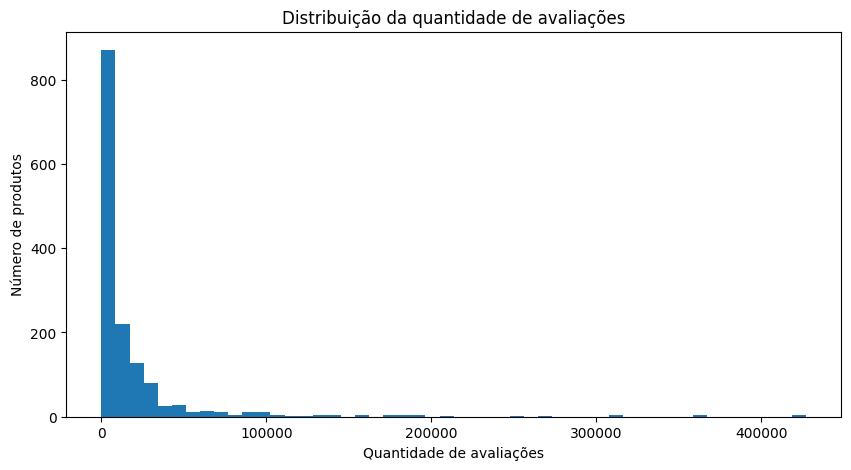

In [ ]:
plt.figure(figsize=(10, 5))
plt.hist(rating_count_num.dropna(), bins=50)
plt.title("Distribuição da quantidade de avaliações")
plt.xlabel("Quantidade de avaliações")
plt.ylabel("Número de produtos")
plt.show()

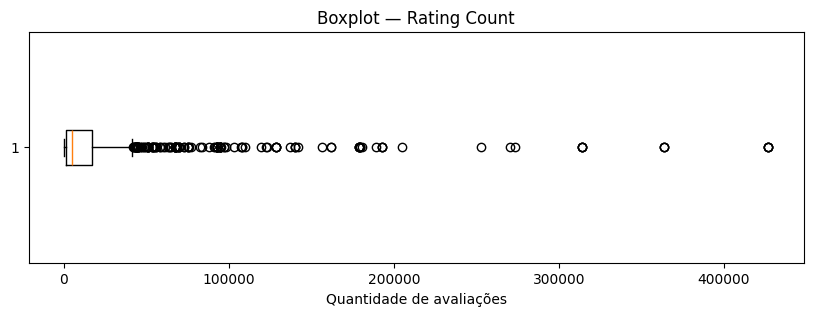

In [ ]:
plt.figure(figsize=(10, 3))
plt.boxplot(rating_count_num.dropna(), vert=False)
plt.title("Boxplot — Rating Count")
plt.xlabel("Quantidade de avaliações")
plt.show()

Os dados comerciais apresentam boa consistência geral. Entretanto, a concentração de avaliações em poucos produtos indica que a média pode não representar adequadamente o comportamento do portfólio. Os valores extremos deverão ser preservados até que sua influência seja avaliada.

In [ ]:
# Quantidade de produtos por categoria original

produtos_categoria = (
    df.drop_duplicates("product_id")
      .groupby("category")["product_id"]
      .nunique()
      .sort_values(ascending=False)
)

print("Categorias distintas:", produtos_categoria.count())

display(produtos_categoria.head(15))

Categorias distintas: 211


,product_id
category,
Computers&Accessories|Accessories&Peripherals|Cables&Accessories|Cables|USBCables,161
Electronics|Mobiles&Accessories|Smartphones&BasicMobiles|Smartphones,68
Electronics|WearableTechnology|SmartWatches,62
"Electronics|HomeTheater,TV&Video|Televisions|SmartTelevisions",60
"Electronics|Headphones,Earbuds&Accessories|Headphones|In-Ear",51
"Electronics|HomeTheater,TV&Video|Accessories|RemoteControls",49
Home&Kitchen|Kitchen&HomeAppliances|SmallKitchenAppliances|MixerGrinders,27
"Home&Kitchen|Kitchen&HomeAppliances|Vacuum,Cleaning&Ironing|Irons,Steamers&Accessories|Irons|DryIrons",24
"Computers&Accessories|Accessories&Peripherals|Keyboards,Mice&InputDevices|Mice",24


In [ ]:
df_produtos = df.drop_duplicates(
    subset="product_id"
).copy()

df_produtos["categoria_principal"] = (
    df_produtos["category"].str.split("|").str[0]
)

categorias_principais = (
    df_produtos["categoria_principal"].value_counts()
)

distribuicao = categorias_principais.to_frame(
    "quantidade_produtos"
)

distribuicao["participacao_%"] = (
    distribuicao["quantidade_produtos"]
    / df_produtos["product_id"].nunique()
    * 100
).round(2)

display(distribuicao)

,quantidade_produtos,participacao_%
categoria_principal,,
Electronics,490,36.27
Home&Kitchen,448,33.16
Computers&Accessories,375,27.76
OfficeProducts,31,2.29
MusicalInstruments,2,0.15
HomeImprovement,2,0.15
Toys&Games,1,0.07
Car&Motorbike,1,0.07
Health&PersonalCare,1,0.07


In [ ]:
# Distribuição percentual das categorias

distribuicao = categorias_principais.to_frame(
    "quantidade_produtos"
)

distribuicao["participacao_%"] = (
    distribuicao["quantidade_produtos"]
    / df_produtos["product_id"].nunique()
    * 100
).round(2)

display(distribuicao)

,quantidade_produtos,participacao_%
categoria_principal,,
Electronics,490,36.27
Home&Kitchen,448,33.16
Computers&Accessories,375,27.76
OfficeProducts,31,2.29
MusicalInstruments,2,0.15
HomeImprovement,2,0.15
Toys&Games,1,0.07
Car&Motorbike,1,0.07
Health&PersonalCare,1,0.07


In [ ]:
colunas = [
    "discounted_price",
    "actual_price",
    "discount_percentage",
    "rating",
    "rating_count"
]

display(df_produtos[colunas].dtypes)

,0
discounted_price,object
actual_price,object
discount_percentage,object
rating,object
rating_count,object


In [ ]:
colunas_numericas = [
    "discounted_price",
    "actual_price",
    "discount_percentage",
    "rating",
    "rating_count"
]

for coluna in colunas_numericas:
    df_produtos[coluna] = (
        df_produtos[coluna]
        .astype(str)
        .str.replace(",", "", regex=False)
        .str.replace("%", "", regex=False)
        .str.replace("₹", "", regex=False)
        .str.strip()
    )

    df_produtos[coluna] = pd.to_numeric(
        df_produtos[coluna],
        errors="coerce"
    )

display(df_produtos[colunas_numericas].dtypes)

,0
discounted_price,float64
actual_price,float64
discount_percentage,int64
rating,float64
rating_count,float64


In [ ]:
resumo_categorias = (
    df_produtos
    .groupby("categoria_principal")
    .agg(
        quantidade_produtos=("product_id", "nunique"),
        preco_medio=("actual_price", "mean"),
        preco_promocional_medio=("discounted_price", "mean"),
        desconto_medio=("discount_percentage", "mean"),
        avaliacao_media=("rating", "mean"),
        avaliacoes_medias=("rating_count", "mean")
    )
    .round(2)
    .sort_values("quantidade_produtos", ascending=False)
)

display(resumo_categorias)

,quantidade_produtos,preco_medio,preco_promocional_medio,desconto_medio,avaliacao_media,avaliacoes_medias
categoria_principal,,,,,,
Electronics,490,10418.08,6225.87,49.91,4.08,28996.75
Home&Kitchen,448,4162.07,2330.62,40.12,4.04,6676.49
Computers&Accessories,375,1857.75,947.49,53.22,4.15,16984.39
OfficeProducts,31,397.19,301.58,12.35,4.31,4828.23
MusicalInstruments,2,1347.00,638.00,46.00,3.90,44441.00
HomeImprovement,2,799.00,337.00,57.50,4.25,4283.00
Car&Motorbike,1,4000.00,2339.00,42.00,3.80,1118.00
Health&PersonalCare,1,1900.00,899.00,53.00,4.00,3663.00
Toys&Games,1,150.00,150.00,0.00,4.30,15867.00


In [ ]:
df_produtos["faixa_desconto"] = pd.cut(
    df_produtos["discount_percentage"],
    bins=[-1, 20, 40, 60, 80, 100],
    labels=["0–20%", "21–40%", "41–60%", "61–80%", "81–100%"]
)

resumo_descontos = (
    df_produtos
    .groupby("faixa_desconto", observed=True)
    .agg(
        quantidade_produtos=("product_id", "nunique"),
        desconto_medio=("discount_percentage", "mean"),
        avaliacao_media=("rating", "mean"),
        avaliacoes_medias=("rating_count", "mean"),
        preco_promocional_medio=("discounted_price", "mean")
    )
    .round(2)
)

display(resumo_descontos)

,quantidade_produtos,desconto_medio,avaliacao_media,avaliacoes_medias,preco_promocional_medio
faixa_desconto,,,,,
0–20%,176,9.92,4.17,14484.36,3870.33
21–40%,329,31.04,4.13,19643.95,6658.48
41–60%,469,51.07,4.07,15242.01,2664.91
61–80%,326,69.85,4.07,22174.49,973.40
81–100%,51,86.08,3.97,8966.29,505.82


observar se existe alguma associação entre intensidade do desconto, avaliação e engajamento.

In [ ]:
df_produtos["faixa_desconto"] = pd.cut(
    df_produtos["discount_percentage"],
    bins=[-1, 20, 40, 60, 80, 100],
    labels=["0–20%", "21–40%", "41–60%", "61–80%", "81–100%"]
)

resumo_descontos = (
    df_produtos
    .groupby("faixa_desconto", observed=True)
    .agg(
        quantidade_produtos=("product_id", "nunique"),
        desconto_medio=("discount_percentage", "mean"),
        avaliacao_media=("rating", "mean"),
        avaliacoes_medias=("rating_count", "mean"),
        preco_promocional_medio=("discounted_price", "mean")
    )
    .round(2)
)

display(resumo_descontos)

,quantidade_produtos,desconto_medio,avaliacao_media,avaliacoes_medias,preco_promocional_medio
faixa_desconto,,,,,
0–20%,176,9.92,4.17,14484.36,3870.33
21–40%,329,31.04,4.13,19643.95,6658.48
41–60%,469,51.07,4.07,15242.01,2664.91
61–80%,326,69.85,4.07,22174.49,973.40
81–100%,51,86.08,3.97,8966.29,505.82


Curiosamente: Por algum motivo, à medida que o desconto aumenta, a avaliação média diminui ligeiramente.

In [ ]:
colunas_correlacao = [
    "discount_percentage",
    "actual_price",
    "discounted_price",
    "rating",
    "rating_count"
]

correlacao = df_produtos[colunas_correlacao].corr(method="spearman").round(3)

display(correlacao)

,discount_percentage,actual_price,discounted_price,rating,rating_count
discount_percentage,1.000,-0.065,-0.367,-0.150,-0.131
actual_price,-0.065,1.000,0.934,0.032,0.109
discounted_price,-0.367,0.934,1.000,0.077,0.146
rating,-0.150,0.032,0.077,1.000,0.193
rating_count,-0.131,0.109,0.146,0.193,1.000


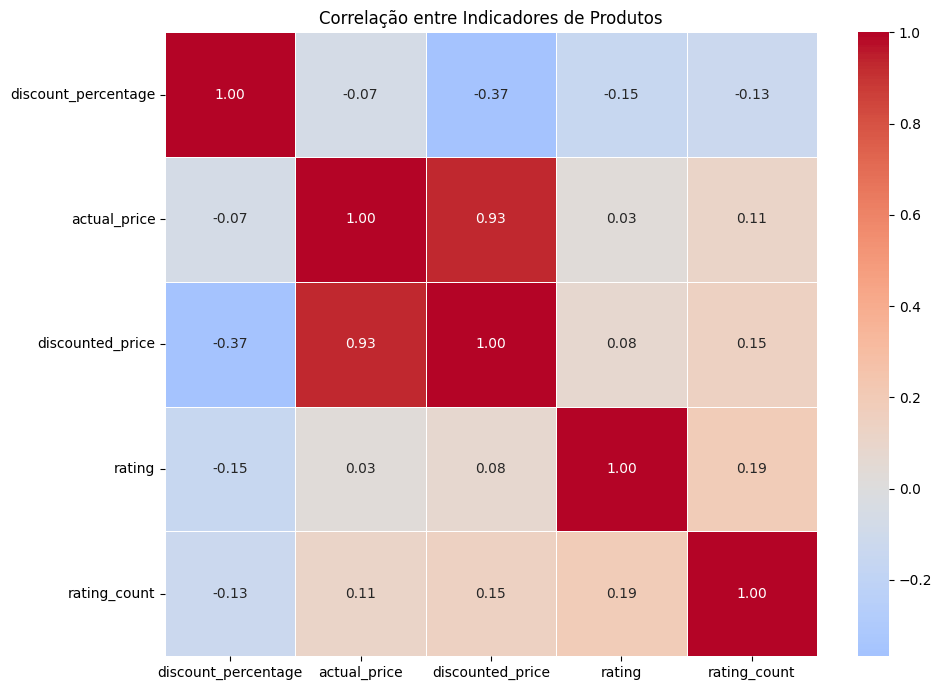

In [ ]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlacao,
    annot=True,
    cmap="coolwarm",
    center=0,
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlação entre Indicadores de Produtos")
plt.tight_layout()
plt.show()

Não há correlações fortes entre desconto, avaliação e engajamento. A relação mais expressiva é entre preço original e promocional (0,93)

###Desempenho individual e engajamento

In [ ]:
top_engajamento = (
    df_produtos[
        [
            "product_id",
            "product_name",
            "categoria_principal",
            "discounted_price",
            "discount_percentage",
            "rating",
            "rating_count"
        ]
    ]
    .sort_values("rating_count", ascending=False)
    .head(15)
)

display(top_engajamento)

,product_id,product_name,categoria_principal,discounted_price,discount_percentage,rating,rating_count
12,B07KSMBL2H,AmazonBasics Flexible Premium HDMI Cable (Blac...,Electronics,219.0,69,4.4,426973.0
65,B014I8SX4Y,"Amazon Basics High-Speed HDMI Cable, 6 Feet (2...",Electronics,309.0,78,4.4,426973.0
47,B014I8SSD0,"Amazon Basics High-Speed HDMI Cable, 6 Feet - ...",Electronics,309.0,35,4.4,426973.0
400,B07GQD4K6L,boAt Bassheads 100 in Ear Wired Earphones with...,Electronics,379.0,62,4.1,363713.0
352,B07GPXXNNG,boAt Bassheads 100 in Ear Wired Earphones with...,Electronics,349.0,65,4.1,363713.0
584,B071Z8M4KX,boAt BassHeads 100 in-Ear Wired Headphones wit...,Electronics,365.0,63,4.1,363711.0
371,B09GFLXVH9,"Redmi 9A Sport (Coral Green, 2GB RAM, 32GB Sto...",Electronics,6499.0,24,4.1,313836.0
370,B09GFPVD9Y,"Redmi 9 Activ (Carbon Black, 4GB RAM, 64GB Sto...",Electronics,8499.0,23,4.1,313836.0
566,B09GFPN6TP,"Redmi 9A Sport (Coral Green, 3GB RAM, 32GB Sto...",Electronics,7499.0,21,4.1,313832.0
473,B09GFM8CGS,"Redmi 9A Sport (Carbon Black, 2GB RAM, 32GB St...",Electronics,6499.0,19,4.1,313832.0


In [ ]:
engajamento_categoria = (
    df_produtos
    .groupby("categoria_principal")
    .agg(
        quantidade_produtos=("product_id", "nunique"),
        total_avaliacoes=("rating_count", "sum"),
        media_avaliacoes=("rating_count", "mean"),
        mediana_avaliacoes=("rating_count", "median")
    )
    .round(2)
    .sort_values("total_avaliacoes", ascending=False)
)

display(engajamento_categoria)

,quantidade_produtos,total_avaliacoes,media_avaliacoes,mediana_avaliacoes
categoria_principal,,,,
Electronics,490,14208406.0,28996.75,9129.5
Computers&Accessories,375,6335177.0,16984.39,7317.0
Home&Kitchen,448,2991069.0,6676.49,2305.5
OfficeProducts,31,149675.0,4828.23,4426.0
MusicalInstruments,2,88882.0,44441.00,44441.0
Toys&Games,1,15867.0,15867.00,15867.0
HomeImprovement,2,8566.0,4283.00,4283.0
Health&PersonalCare,1,3663.0,3663.00,3663.0
Car&Motorbike,1,1118.0,1118.00,1118.0


In [ ]:
mediana_engajamento = df_produtos["rating_count"].median()

produtos_atencao = (
    df_produtos[
        (df_produtos["rating_count"] >= mediana_engajamento) &
        (df_produtos["rating"] < 4.0)
    ]
    [
        [
            "product_id",
            "product_name",
            "categoria_principal",
            "discounted_price",
            "discount_percentage",
            "rating",
            "rating_count"
        ]
    ]
    .sort_values("rating_count", ascending=False)
)

print("Mediana de avaliações:", mediana_engajamento)
print("Produtos com alto engajamento e rating abaixo de 4,0:",
      len(produtos_atencao))

display(produtos_atencao.head(20))

Mediana de avaliações: 4740.0
Produtos com alto engajamento e rating abaixo de 4,0: 112


,product_id,product_name,categoria_principal,discounted_price,discount_percentage,rating,rating_count
591,B08JQN8DGZ,boAt Airdopes 121v2 in-Ear True Wireless Earbu...,Electronics,1299.0,57,3.8,180998.0
585,B09N3ZNHTY,boAt Airdopes 141 Bluetooth Truly Wireless in ...,Electronics,1499.0,67,3.9,136954.0
1022,B07WMS7TWB,Pigeon by Stovekraft Amaze Plus Electric Kettl...,Home&Kitchen,649.0,48,3.9,123365.0
656,B07LG59NPV,Boult Audio Probass Curve Bluetooth Wireless i...,Electronics,899.0,80,3.8,103052.0
601,B07JQKQ91F,"JBL C50HI, Wired in Ear Headphones with Mic, O...",Electronics,499.0,50,3.9,92995.0
716,B08FB2LNSZ,"JBL Tune 215BT, 16 Hrs Playtime with Quick Cha...",Electronics,1499.0,50,3.7,87798.0
415,B085W8CFLH,PTron Tangent Lite Bluetooth 5.0 Earphones wit...,Electronics,599.0,67,3.5,83996.0
609,B07TCN5VR9,Boult Audio BassBuds X1 in-Ear Wired Earphones...,Electronics,329.0,67,3.9,77027.0
712,B07YNTJ8ZM,Zebronics ZEB-COUNTY 3W Wireless Bluetooth Por...,Electronics,549.0,45,3.9,64705.0
1031,B01MQZ7J8K,"Prestige Electric Kettle PKOSS - 1500watts, St...",Home&Kitchen,749.0,48,3.9,63350.0


In [ ]:
atencao_categoria = (
    produtos_atencao
    .groupby("categoria_principal")
    .agg(
        quantidade_produtos=("product_id", "nunique"),
        media_rating=("rating", "mean"),
        media_avaliacoes=("rating_count", "mean"),
        desconto_medio=("discount_percentage", "mean")
    )
    .round(2)
    .sort_values("quantidade_produtos", ascending=False)
)

display(atencao_categoria)

,quantidade_produtos,media_rating,media_avaliacoes,desconto_medio
categoria_principal,,,,
Electronics,50,3.81,33328.44,58.88
Home&Kitchen,33,3.82,22421.48,39.97
Computers&Accessories,28,3.66,13211.04,46.54
MusicalInstruments,1,3.80,20218.00,32.00


In [ ]:
produtos_potencial = (
    df_produtos[
        (df_produtos["rating"] >= 4.5) &
        (df_produtos["rating_count"] < mediana_engajamento)
    ]
    [[
        "product_id",
        "product_name",
        "categoria_principal",
        "discounted_price",
        "discount_percentage",
        "rating",
        "rating_count"
    ]]
    .sort_values(
        ["rating", "rating_count"],
        ascending=[False, True]
    )
)

print("Produtos com boa avaliação e baixa visibilidade:",
      len(produtos_potencial))

display(produtos_potencial.head(20))

Produtos com boa avaliação e baixa visibilidade: 46


,product_id,product_name,categoria_principal,discounted_price,discount_percentage,rating,rating_count
174,B0BP7XLX48,Syncwire LTG to USB Cable for Fast Charging Co...,Computers&Accessories,399.0,80,5.0,5.0
775,B09ZHCJDP1,Amazon Basics Wireless Mouse | 2.4 GHz Connect...,Computers&Accessories,499.0,50,5.0,23.0
1201,B0BQ3K23Y1,"Oratech Coffee Frother electric, milk frother ...",Home&Kitchen,279.0,44,4.8,28.0
1299,B0B53DS4TF,"Instant Pot Air Fryer, Vortex 2QT, Touch Contr...",Home&Kitchen,4995.0,75,4.8,3964.0
1226,B0BLC2BYPX,Zuvexa USB Rechargeable Electric Foam Maker - ...,Home&Kitchen,499.0,62,4.7,54.0
1223,B0BM4KTNL1,"FIGMENT Handheld Milk Frother Rechargeable, 3-...",Home&Kitchen,699.0,56,4.7,1729.0
1275,B0BM9H2NY9,Multifunctional 2 in 1 Electric Egg Boiling St...,Home&Kitchen,699.0,56,4.7,2300.0
1388,B0BP89YBC1,Campfire Spring Chef Prolix Instant Portable W...,Home&Kitchen,1499.0,57,4.7,2591.0
1293,B09P1MFKG1,Melbon VM-905 2000-Watt Room Heater (ISI Certi...,Home&Kitchen,998.0,67,4.6,9.0
1216,B0BN6M3TCM,"VRPRIME Lint Roller Lint Remover for Clothes, ...",Home&Kitchen,499.0,50,4.6,79.0


Produtos bem avaliados que ainda possuem menor visibilidade

In [ ]:
oportunidade_categoria = (
    produtos_potencial
    .groupby("categoria_principal")
    .agg(
        quantidade_produtos=("product_id", "nunique"),
        avaliacao_media=("rating", "mean"),
        media_avaliacoes=("rating_count", "mean"),
        desconto_medio=("discount_percentage", "mean")
    )
    .round(2)
    .sort_values("quantidade_produtos", ascending=False)
)

display(oportunidade_categoria)

,quantidade_produtos,avaliacao_media,media_avaliacoes,desconto_medio
categoria_principal,,,,
Home&Kitchen,21,4.60,1209.76,49.86
Computers&Accessories,13,4.58,1348.62,51.00
Electronics,9,4.52,870.44,57.44
OfficeProducts,3,4.50,3295.67,7.33


In [ ]:
df_prioridades = df_produtos.copy()

df_prioridades["nivel_engajamento"] = np.where(
    df_prioridades["rating_count"] >= mediana_engajamento,
    "Alto",
    "Baixo"
)

df_prioridades["nivel_satisfacao"] = np.where(
    df_prioridades["rating"] >= 4.5,
    "Alta",
    "Baixa"
)

df_prioridades["grupo_prioridade"] = (
    df_prioridades["nivel_engajamento"] + " engajamento / " +
    df_prioridades["nivel_satisfacao"] + " satisfação"
)

resumo_prioridades = (
    df_prioridades
    .groupby("grupo_prioridade")
    .agg(
        quantidade_produtos=("product_id", "nunique"),
        avaliacao_media=("rating", "mean"),
        media_avaliacoes=("rating_count", "mean"),
        desconto_medio=("discount_percentage", "mean")
    )
    .round(2)
)

display(resumo_prioridades)

,quantidade_produtos,avaliacao_media,media_avaliacoes,desconto_medio
grupo_prioridade,,,,
Alto engajamento / Alta satisfação,49,4.53,27389.61,36.06
Alto engajamento / Baixa satisfação,626,4.12,34258.74,44.64
Baixo engajamento / Alta satisfação,47,4.58,1318.65,49.45
Baixo engajamento / Baixa satisfação,629,4.00,1518.64,49.34


In [ ]:
matriz_categoria = (
    df_prioridades
    .groupby(["categoria_principal", "grupo_prioridade"])
    .size()
    .unstack(fill_value=0)
)

matriz_categoria["total_produtos"] = matriz_categoria.sum(axis=1)

matriz_categoria["alto_engajamento_baixa_satisfacao_%"] = (
    matriz_categoria["Alto engajamento / Baixa satisfação"] /
    matriz_categoria["total_produtos"] * 100
).round(2)

display(
    matriz_categoria.sort_values(
        "alto_engajamento_baixa_satisfacao_%",
        ascending=False
    )
)

grupo_prioridade,Alto engajamento / Alta satisfação,Alto engajamento / Baixa satisfação,Baixo engajamento / Alta satisfação,Baixo engajamento / Baixa satisfação,total_produtos,alto_engajamento_baixa_satisfacao_%
categoria_principal,,,,,,
Toys&Games,0,1,0,0,1,100.00
MusicalInstruments,0,2,0,0,2,100.00
Electronics,13,280,9,188,490,57.14
Computers&Accessories,23,190,14,148,375,50.67
OfficeProducts,4,10,3,14,31,32.26
Home&Kitchen,8,143,21,276,448,31.92
Car&Motorbike,0,0,0,1,1,0.00
Health&PersonalCare,0,0,0,1,1,0.00
HomeImprovement,1,0,0,1,2,0.00


A popularidade dos produtos não garante satisfação elevada. Foram identificados grupos que merecem investigação, especialmente em Electronics e Computers&Accessories, além de oportunidades potenciais de visibilidade em Home&Kitchen.

###Customer Insights

In [ ]:
colunas_reviews = [
    "product_id",
    "product_name",
    "rating",
    "review_title",
    "review_content"
]

display(df_produtos[colunas_reviews].head(10))

,product_id,product_name,rating,review_title,review_content
0,B07JW9H4J1,Wayona Nylon Braided USB to Lightning Fast Cha...,4.2,"Satisfied,Charging is really fast,Value for mo...",Looks durable Charging is fine tooNo complains...
1,B098NS6PVG,Ambrane Unbreakable 60W / 3A Fast Charging 1.5...,4.0,"A Good Braided Cable for Your Type C Device,Go...",I ordered this cable to connect my phone to An...
2,B096MSW6CT,Sounce Fast Phone Charging Cable & Data Sync U...,3.9,"Good speed for earlier versions,Good Product,W...","Not quite durable and sturdy,https://m.media-a..."
3,B08HDJ86NZ,boAt Deuce USB 300 2 in 1 Type-C & Micro USB S...,4.2,"Good product,Good one,Nice,Really nice product...","Good product,long wire,Charges good,Nice,I bou..."
4,B08CF3B7N1,Portronics Konnect L 1.2M Fast Charging 3A 8 P...,4.2,"As good as original,Decent,Good one for second...","Bought this instead of original apple, does th..."
5,B08Y1TFSP6,pTron Solero TB301 3A Type-C Data and Fast Cha...,3.9,"It's pretty good,Average quality,very good and...","It's a good product.,Like,Very good item stron..."
6,B08WRWPM22,"boAt Micro USB 55 Tangle-free, Sturdy Micro US...",4.1,"Long durable.,good,Does not charge Lenovo m8 t...",Build quality is good and it is comes with 2 y...
7,B08DDRGWTJ,MI Usb Type-C Cable Smartphone (Black),4.3,"Worth for money - suitable for Android auto,Go...",Worth for money - suitable for Android auto......
8,B008IFXQFU,"TP-Link USB WiFi Adapter for PC(TL-WN725N), N1...",4.2,Works on linux for me. Get the model with ante...,I use this to connect an old PC to internet. I...
9,B082LZGK39,Ambrane Unbreakable 60W / 3A Fast Charging 1.5...,4.0,"A Good Braided Cable for Your Type C Device,Go...",I ordered this cable to connect my phone to An...


In [ ]:
faixas = [
    (df_produtos["rating"] <= 3.0),
    (df_produtos["rating"].between(3.1, 3.9)),
    (df_produtos["rating"] >= 4.0)
]

rotulos = [
    "Baixa (1,0–3,0)",
    "Intermediária (3,1–3,9)",
    "Alta (4,0–5,0)"
]

df_produtos["faixa_rating"] = np.select(
    faixas,
    rotulos,
    default="Não classificado"
)

display(
    df_produtos["faixa_rating"]
    .value_counts()
    .reindex(rotulos)
    .to_frame("quantidade_produtos")
    .assign(
        percentual=lambda x:
        (x["quantidade_produtos"] / len(df_produtos) * 100).round(2)
    )
)

,quantidade_produtos,percentual
faixa_rating,,
"Baixa (1,0–3,0)",10,0.74
"Intermediária (3,1–3,9)",330,24.43
"Alta (4,0–5,0)",1010,74.76


In [ ]:
condicoes = [
    df_produtos["rating"].between(1.0, 2.0),
    df_produtos["rating"].between(2.1, 3.0),
    df_produtos["rating"].between(3.1, 3.9),
    df_produtos["rating"].between(4.0, 4.5),
    df_produtos["rating"].between(4.6, 5.0)
]

rotulos = [
    "Crítica (1,0–2,0)",
    "Baixa (2,1–3,0)",
    "Intermediária (3,1–3,9)",
    "Alta (4,0–4,5)",
    "Excepcional (4,6–5,0)"
]

df_produtos["faixa_rating"] = np.select(
    condicoes,
    rotulos,
    default="Não classificado"
)

resumo_rating = (
    df_produtos["faixa_rating"]
    .value_counts()
    .reindex(rotulos)
    .to_frame("quantidade_produtos")
)

resumo_rating["percentual"] = (
    resumo_rating["quantidade_produtos"] /
    len(df_produtos) * 100
).round(2)

display(resumo_rating)

,quantidade_produtos,percentual
faixa_rating,,
"Crítica (1,0–2,0)",1,0.07
"Baixa (2,1–3,0)",9,0.67
"Intermediária (3,1–3,9)",330,24.43
"Alta (4,0–4,5)",982,72.69
"Excepcional (4,6–5,0)",28,2.07


In [ ]:
resumo_engajamento = (
    df_produtos.groupby("faixa_rating")
    .agg(
        quantidade_produtos=("product_id", "count"),
        media_avaliacoes=("rating_count", "mean"),
        mediana_avaliacoes=("rating_count", "median"),
        total_avaliacoes=("rating_count", "sum")
    )
    .reindex(rotulos)
    .round(2)
)

display(resumo_engajamento)

,quantidade_produtos,media_avaliacoes,mediana_avaliacoes,total_avaliacoes
faixa_rating,,,,
"Crítica (1,0–2,0)",1,2.00,2.0,2.0
"Baixa (2,1–3,0)",9,224.12,106.0,1793.0
"Intermediária (3,1–3,9)",330,9259.23,1987.0,3055547.0
"Alta (4,0–4,5)",982,20923.33,6399.0,20546712.0
"Excepcional (4,6–5,0)",28,7310.26,2781.0,197377.0


In [ ]:
produtos_excepcionais = (
    df_produtos[
        df_produtos["faixa_rating"] == "Excepcional (4,6–5,0)"
    ][[
        "product_name",
        "rating",
        "rating_count",
        "discount_percentage",
        "discounted_price"
    ]]
    .sort_values(
        by=["rating", "rating_count"],
        ascending=[False, False]
    )
)

display(produtos_excepcionais)

,product_name,rating,rating_count,discount_percentage,discounted_price
775,Amazon Basics Wireless Mouse | 2.4 GHz Connect...,5.0,23.0,50,499.0
174,Syncwire LTG to USB Cable for Fast Charging Co...,5.0,5.0,80,399.0
324,"REDTECH USB-C to Lightning Cable 3.3FT, [Apple...",5.0,NaN,75,249.0
1145,Swiffer Instant Electric Water Heater Faucet T...,4.8,53803.0,28,1439.0
1299,"Instant Pot Air Fryer, Vortex 2QT, Touch Contr...",4.8,3964.0,75,4995.0
1201,"Oratech Coffee Frother electric, milk frother ...",4.8,28.0,44,279.0
459,Spigen EZ Fit Tempered Glass Screen Protector ...,4.7,7779.0,66,999.0
249,Sony Bravia 164 cm (65 inches) 4K Ultra HD Sma...,4.7,5935.0,44,77990.0
1388,Campfire Spring Chef Prolix Instant Portable W...,4.7,2591.0,57,1499.0
1275,Multifunctional 2 in 1 Electric Egg Boiling St...,4.7,2300.0,56,699.0


In [ ]:
df_excepcionais = df_produtos[
    df_produtos["faixa_rating"] == "Excepcional (4,6–5,0)"
].copy()

df_excepcionais["nivel_engajamento"] = pd.cut(
    df_excepcionais["rating_count"],
    bins=[-1, 1000, 10000, float("inf")],
    labels=[
        "Baixo (até 1.000)",
        "Intermediário (1.001–10.000)",
        "Alto (acima de 10.000)"
    ]
)

display(
    df_excepcionais.groupby(
        "nivel_engajamento",
        observed=False
    )
    .agg(
        quantidade_produtos=("product_id", "count"),
        rating_medio=("rating", "mean"),
        mediana_avaliacoes=("rating_count", "median")
    )
    .round(2)
)

,quantidade_produtos,rating_medio,mediana_avaliacoes
nivel_engajamento,,,
Baixo (até 1.000),9,4.72,54.0
Intermediário (1.001–10.000),12,4.66,3275.0
Alto (acima de 10.000),6,4.63,19489.0


Temos 27 produtos classificados, enquanto um ficou sem rating_count e, corretamente, não entrou nos grupos de engajamento.

In [ ]:
oportunidades_categoria = (
    df_excepcionais[
        df_excepcionais["nivel_engajamento"] == "Baixo (até 1.000)"
    ]
    .groupby("categoria_principal")
    .agg(
        quantidade_produtos=("product_id", "count"),
        rating_medio=("rating", "mean"),
        media_avaliacoes=("rating_count", "mean")
    )
    .sort_values(
        by="quantidade_produtos",
        ascending=False
    )
    .round(2)
)

display(oportunidades_categoria)

,quantidade_produtos,rating_medio,media_avaliacoes
categoria_principal,,,
Home&Kitchen,6,4.65,69.67
Computers&Accessories,2,5.00,14.00
Electronics,1,4.60,245.00


Podemos levantar a hipótese de que existem produtos com boa percepção inicial dos consumidores, mas que ainda não alcançaram visibilidade proporcional.

In [ ]:
produtos_oportunidade = df_excepcionais[
    (df_excepcionais["nivel_engajamento"] == "Baixo (até 1.000)") &
    (df_excepcionais["rating_count"].notna())
]

colunas_insights = [
    "product_name",
    "categoria_principal",
    "rating",
    "rating_count",
    "review_title",
    "review_content"
]

display(produtos_oportunidade[colunas_insights])

,product_name,categoria_principal,rating,rating_count,review_title,review_content
174,Syncwire LTG to USB Cable for Fast Charging Co...,Computers&Accessories,5.0,5.0,"Good,Superb quality,Good products nice one,Wo...",Product is good in quality. Working good with ...
571,"WeCool S5 Long Selfie Stick, with Large Reinfo...",Electronics,4.6,245.0,"Good,Good Product but Little expensive.,Happy ...","Good,Thoda sa kam stable hai, phone lagane ke ..."
775,Amazon Basics Wireless Mouse | 2.4 GHz Connect...,Computers&Accessories,5.0,23.0,"Very responsive and stylish mouse,Simply Aweso...",I really like this wireless mouse it has becam...
1119,Lint Remover Woolen Clothes Lint Extractor Bat...,Home&Kitchen,4.6,124.0,"good,Overall good product but got stop inbetwe...",https://m.media-amazon.com/images/W/WEBP_40237...
1201,"Oratech Coffee Frother electric, milk frother ...",Home&Kitchen,4.8,28.0,"Oratech Best Coffee Frother,Great,My review ab...","Overall, I love this Oratech Coffee frother an..."
1216,"VRPRIME Lint Roller Lint Remover for Clothes, ...",Home&Kitchen,4.6,79.0,"Superb,Very helpful and great quality,Exactly ...","Value for money,The quality of the tapes are a..."
1226,Zuvexa USB Rechargeable Electric Foam Maker - ...,Home&Kitchen,4.7,54.0,"Little kitchen helper,An amazing product,Very ...",The first time I tried it send the eggs and th...
1289,Aquadpure Copper + Mineral RO+UV+UF 10 to 12 L...,Home&Kitchen,4.6,124.0,"service is excellent, installation guy is ver...","I like the service most and the product,Note: ..."
1293,Melbon VM-905 2000-Watt Room Heater (ISI Certi...,Home&Kitchen,4.6,9.0,"It's good,Happy to purchase,Product is really ...","It's good nd amazing product,Very nice produc..."


De maneira geral, isto é uma leitura exploratória dos textos exibidos, não uma análise de frequência ou sentimento de todos os comentários. Além disso, os nove produtos foram selecionados justamente por terem ratings altos e baixo engajamento; não representam todo o portfólio. Por isso é importante avaliar os produtos de rating 3 para ter uma bom comparativo

In [ ]:
produtos_insatisfacao = df_produtos[
    df_produtos["rating"] <= 3.0
]

display(
    produtos_insatisfacao[
        [
            "product_name",
            "categoria_principal",
            "rating",
            "rating_count",
            "review_title",
            "review_content"
        ]
    ]
)

,product_name,categoria_principal,rating,rating_count,review_title,review_content
263,7SEVEN Compatible LG TV Remote Suitable for LG...,Electronics,3.0,103.0,"Not good,No voice recognition, No pointer ray ...",The mouse feature of the remote is not working...
282,Amazon Brand - Solimo 65W Fast Charging Braide...,Computers&Accessories,3.0,NaN,The cable works but is not 65W as advertised,I have a pd supported car charger and I bought...
545,SHREENOVA ID116 Plus Bluetooth Fitness Smart W...,Electronics,2.8,87.0,"Very Good prodat,Battery life is 0 day,Good,Wh...","Good Prodat,Battery life is so bad.,Nice produ..."
550,Tokdis MX-1 Pro Bluetooth Calling Smartwatch -...,Electronics,3.0,681.0,"Its is good but battery life is very poor,Hear...","Its is value for money,,Good product,Good, lik..."
1243,"Personal Size Blender, Portable Blender, Batte...",Home&Kitchen,2.3,13.0,"Nice product i recommend to buy,Do not buy!! D...","I liked that it is so convenient to carry,Wast..."
1286,MR. BRAND Portable USB Juicer Electric USB Jui...,Home&Kitchen,2.8,109.0,"Portable but not much powerful,not so good. po...","Not sufficient power,the product is more like ..."
1309,Khaitan ORFin Fan heater for Home and kitchen-...,Home&Kitchen,2.0,2.0,"Bad quality,Amazing product..",The heating capacity is zero .Moreover i have ...
1315,"Nirdambhay Mini Bag Sealer, 2 in 1 Heat Sealer...",Home&Kitchen,3.0,617.0,"Not worth the hype,Gud,Really useful 😃,Product...",Hi viewers so I bought this product after watc...
1356,Green Tales Heat Seal Mini Food Sealer-Impulse...,Home&Kitchen,2.6,24.0,"It is broken,Could have been a bit better,The ...",It is broken and it is not useful. Please chan...
1449,IONIX Tap filter Multilayer | Activated Carbon...,Home&Kitchen,2.9,159.0,"Stop working after few days,Ok. Changing every...","Stop working after few days,Ok,It doesn't fit ..."


A insatisfação parece estar fortemente relacionada à diferença entre expectativa e entrega: o consumidor espera determinada funcionalidade, desempenho ou durabilidade, mas o produto não corresponde ao prometido. Algo normal, mas que é importante destacar. Principalmente quando a satisfação do cliente é um dos KPIs mais importantes do negócio

In [ ]:
resumo_insatisfacao = (
    produtos_insatisfacao
    .groupby("categoria_principal")
    .agg(
        quantidade_produtos=("product_id", "count"),
        rating_medio=("rating", "mean"),
        media_avaliacoes=("rating_count", "mean")
    )
    .sort_values(
        by="quantidade_produtos",
        ascending=False
    )
    .round(2)
)

display(resumo_insatisfacao)


,quantidade_produtos,rating_medio,media_avaliacoes
categoria_principal,,,
Home&Kitchen,6,2.60,154.00
Electronics,3,2.93,290.33
Computers&Accessories,1,3.00,NaN


**Customer Insights**
Pela análise temos quatro achados importantes:
1. Predominância de avaliações positivas: 97,0% dos produtos possuem rating igual ou superior a 3,1.
2. Oportunidades de visibilidade: nove produtos com rating entre 4,6 e 5,0 apresentam até 1.000 avaliações.
3. Problemas de experiência: os produtos com rating até 3,0 apresentam relatos de falhas, desempenho insuficiente, autonomia e divergências entre especificações e entrega.
4. Concentração de insatisfação: Home&Kitchen representa seis dos dez produtos com rating até 3,0.

###Consolidação dos indicadores

In [ ]:
indicadores_gerais = pd.DataFrame({
    "indicador": [
        "Total de produtos",
        "Categorias principais",
        "Preço médio original",
        "Preço médio promocional",
        "Desconto médio",
        "Rating médio",
        "Mediana de avaliações",
        "Total de avaliações"
    ],
    "valor": [
        df_produtos["product_id"].nunique(),
        df_produtos["categoria_principal"].nunique(),
        df_produtos["actual_price"].mean(),
        df_produtos["discounted_price"].mean(),
        df_produtos["discount_percentage"].mean(),
        df_produtos["rating"].mean(),
        df_produtos["rating_count"].median(),
        df_produtos["rating_count"].sum()
    ]
})

display(indicadores_gerais.round(2))

,indicador,valor
0,Total de produtos,1351.00
1,Categorias principais,9.00
2,Preço médio original,5691.18
3,Preço médio promocional,3304.80
4,Desconto médio,46.69
5,Rating médio,4.09
6,Mediana de avaliações,4740.00
7,Total de avaliações,23802423.00


In [ ]:
indicadores_categoria = (
    df_produtos.groupby("categoria_principal")
    .agg(
        quantidade_produtos=("product_id", "nunique"),
        preco_medio_original=("actual_price", "mean"),
        preco_medio_promocional=("discounted_price", "mean"),
        desconto_medio=("discount_percentage", "mean"),
        rating_medio=("rating", "mean"),
        mediana_avaliacoes=("rating_count", "median"),
        total_avaliacoes=("rating_count", "sum")
    )
    .sort_values(
        by="quantidade_produtos",
        ascending=False
    )
    .round(2)
)

display(indicadores_categoria)

,quantidade_produtos,preco_medio_original,preco_medio_promocional,desconto_medio,rating_medio,mediana_avaliacoes,total_avaliacoes
categoria_principal,,,,,,,
Electronics,490,10418.08,6225.87,49.91,4.08,9129.5,14208406.0
Home&Kitchen,448,4162.07,2330.62,40.12,4.04,2305.5,2991069.0
Computers&Accessories,375,1857.75,947.49,53.22,4.15,7317.0,6335177.0
OfficeProducts,31,397.19,301.58,12.35,4.31,4426.0,149675.0
MusicalInstruments,2,1347.00,638.00,46.00,3.90,44441.0,88882.0
HomeImprovement,2,799.00,337.00,57.50,4.25,4283.0,8566.0
Car&Motorbike,1,4000.00,2339.00,42.00,3.80,1118.0,1118.0
Health&PersonalCare,1,1900.00,899.00,53.00,4.00,3663.0,3663.0
Toys&Games,1,150.00,150.00,0.00,4.30,15867.0,15867.0


In [ ]:
top_produtos = (
    df_produtos[
        [
            "product_name",
            "categoria_principal",
            "rating",
            "rating_count",
            "discount_percentage",
            "discounted_price"
        ]
    ]
    .sort_values(
        by="rating_count",
        ascending=False
    )
    .head(15)
)

display(top_produtos)

,product_name,categoria_principal,rating,rating_count,discount_percentage,discounted_price
12,AmazonBasics Flexible Premium HDMI Cable (Blac...,Electronics,4.4,426973.0,69,219.0
65,"Amazon Basics High-Speed HDMI Cable, 6 Feet (2...",Electronics,4.4,426973.0,78,309.0
47,"Amazon Basics High-Speed HDMI Cable, 6 Feet - ...",Electronics,4.4,426973.0,35,309.0
400,boAt Bassheads 100 in Ear Wired Earphones with...,Electronics,4.1,363713.0,62,379.0
352,boAt Bassheads 100 in Ear Wired Earphones with...,Electronics,4.1,363713.0,65,349.0
584,boAt BassHeads 100 in-Ear Wired Headphones wit...,Electronics,4.1,363711.0,63,365.0
371,"Redmi 9A Sport (Coral Green, 2GB RAM, 32GB Sto...",Electronics,4.1,313836.0,24,6499.0
370,"Redmi 9 Activ (Carbon Black, 4GB RAM, 64GB Sto...",Electronics,4.1,313836.0,23,8499.0
566,"Redmi 9A Sport (Coral Green, 3GB RAM, 32GB Sto...",Electronics,4.1,313832.0,21,7499.0
473,"Redmi 9A Sport (Carbon Black, 2GB RAM, 32GB St...",Electronics,4.1,313832.0,19,6499.0


In [ ]:
total_avaliacoes = df_produtos["rating_count"].sum()

top_10_avaliacoes = (
    df_produtos
    .sort_values("rating_count", ascending=False)
    .head(10)["rating_count"]
    .sum()
)

top_20_avaliacoes = (
    df_produtos
    .sort_values("rating_count", ascending=False)
    .head(20)["rating_count"]
    .sum()
)

concentracao_engajamento = pd.DataFrame({
    "grupo": ["Top 10 produtos", "Top 20 produtos"],
    "total_avaliacoes": [top_10_avaliacoes, top_20_avaliacoes],
    "participacao_total_%": [
        top_10_avaliacoes / total_avaliacoes * 100,
        top_20_avaliacoes / total_avaliacoes * 100
    ]
})

display(concentracao_engajamento.round(2))

,grupo,total_avaliacoes,participacao_total_%
0,Top 10 produtos,3627392.0,15.24
1,Top 20 produtos,5743965.0,24.13


In [ ]:
concentracao_categoria = (
    df_produtos
    .groupby("categoria_principal")
    .agg(
        quantidade_produtos=("product_id", "nunique"),
        total_avaliacoes=("rating_count", "sum")
    )
)

concentracao_categoria["participacao_produtos_%"] = (
    concentracao_categoria["quantidade_produtos"]
    / concentracao_categoria["quantidade_produtos"].sum() * 100
)

concentracao_categoria["participacao_avaliacoes_%"] = (
    concentracao_categoria["total_avaliacoes"]
    / concentracao_categoria["total_avaliacoes"].sum() * 100
)

concentracao_categoria = concentracao_categoria.sort_values(
    "total_avaliacoes", ascending=False
).round(2)

display(concentracao_categoria)

,quantidade_produtos,total_avaliacoes,participacao_produtos_%,participacao_avaliacoes_%
categoria_principal,,,,
Electronics,490,14208406.0,36.27,59.69
Computers&Accessories,375,6335177.0,27.76,26.62
Home&Kitchen,448,2991069.0,33.16,12.57
OfficeProducts,31,149675.0,2.29,0.63
MusicalInstruments,2,88882.0,0.15,0.37
Toys&Games,1,15867.0,0.07,0.07
HomeImprovement,2,8566.0,0.15,0.04
Health&PersonalCare,1,3663.0,0.07,0.02
Car&Motorbike,1,1118.0,0.07,0.00


In [ ]:
concentracao_categoria["indice_engajamento"] = (
    concentracao_categoria["participacao_avaliacoes_%"]
    / concentracao_categoria["participacao_produtos_%"]
)

display(
    concentracao_categoria[
        [
            "participacao_produtos_%",
            "participacao_avaliacoes_%",
            "indice_engajamento"
        ]
    ].sort_values(
        "indice_engajamento",
        ascending=False
    ).round(2)
)


,participacao_produtos_%,participacao_avaliacoes_%,indice_engajamento
categoria_principal,,,
MusicalInstruments,0.15,0.37,2.47
Electronics,36.27,59.69,1.65
Toys&Games,0.07,0.07,1.00
Computers&Accessories,27.76,26.62,0.96
Home&Kitchen,33.16,12.57,0.38
Health&PersonalCare,0.07,0.02,0.29
OfficeProducts,2.29,0.63,0.28
HomeImprovement,0.15,0.04,0.27
Car&Motorbike,0.07,0.00,0.00


Melhor trabalhar com grupos menores e contemplar todas as categorias

In [ ]:
mapa_grupos = {
    "Electronics": "Tecnologia e Eletrônicos",
    "Computers&Accessories": "Tecnologia e Eletrônicos",
    "Home&Kitchen": "Casa e Utilidades",
    "HomeImprovement": "Casa e Utilidades",
    "OfficeProducts": "Escritório e Instrumentos",
    "MusicalInstruments": "Escritório e Instrumentos",
    "Toys&Games": "Outros",
    "Health&PersonalCare": "Outros",
    "Car&Motorbike": "Outros"
}

df_produtos["grupo_categoria"] = (
    df_produtos["categoria_principal"].map(mapa_grupos)
)

display(
    df_produtos["grupo_categoria"]
    .value_counts()
    .to_frame("quantidade_produtos")
)

,quantidade_produtos
grupo_categoria,
Tecnologia e Eletrônicos,865
Casa e Utilidades,450
Escritório e Instrumentos,33
Outros,3


In [ ]:
indicadores_grupo = (
    df_produtos
    .groupby("grupo_categoria")
    .agg(
        quantidade_produtos=("product_id", "nunique"),
        preco_medio_original=("actual_price", "mean"),
        preco_medio_promocional=("discounted_price", "mean"),
        desconto_medio=("discount_percentage", "mean"),
        rating_medio=("rating", "mean"),
        mediana_avaliacoes=("rating_count", "median"),
        total_avaliacoes=("rating_count", "sum")
    )
)

indicadores_grupo["participacao_produtos_%"] = (
    indicadores_grupo["quantidade_produtos"]
    / indicadores_grupo["quantidade_produtos"].sum() * 100
)

indicadores_grupo["participacao_avaliacoes_%"] = (
    indicadores_grupo["total_avaliacoes"]
    / indicadores_grupo["total_avaliacoes"].sum() * 100
)

indicadores_grupo["indice_engajamento"] = (
    indicadores_grupo["participacao_avaliacoes_%"]
    / indicadores_grupo["participacao_produtos_%"]
)

display(
    indicadores_grupo.sort_values(
        "quantidade_produtos",
        ascending=False
    ).round(2)
)

,quantidade_produtos,preco_medio_original,preco_medio_promocional,desconto_medio,rating_medio,mediana_avaliacoes,total_avaliacoes,participacao_produtos_%,participacao_avaliacoes_%,indice_engajamento
grupo_categoria,,,,,,,,,,
Tecnologia e Eletrônicos,865,6706.95,3937.55,51.34,4.11,7807.0,20543583.0,64.03,86.31,1.35
Casa e Utilidades,450,4147.13,2321.76,40.20,4.04,2318.5,2999635.0,33.31,12.60,0.38
Escritório e Instrumentos,33,454.76,321.97,14.39,4.28,4428.0,238557.0,2.44,1.00,0.41
Outros,3,2016.67,1129.33,31.67,4.03,3663.0,20648.0,0.22,0.09,0.39


In [ ]:
# Classificação de satisfação
df_produtos["faixa_satisfacao"] = pd.cut(
    df_produtos["rating"],
    bins=[0, 2, 3, 3.9, 4.5, 5],
    labels=[
        "Crítica",
        "Baixa",
        "Intermediária",
        "Alta",
        "Excepcional"
    ],
    include_lowest=True
)

# Mediana de avaliações dentro de cada grupo
df_produtos["mediana_grupo"] = (
    df_produtos.groupby("grupo_categoria")["rating_count"]
    .transform("median")
)

# Classificação de engajamento relativo
df_produtos["nivel_engajamento_grupo"] = "Baixo"

df_produtos.loc[
    df_produtos["rating_count"] > df_produtos["mediana_grupo"],
    "nivel_engajamento_grupo"
] = "Alto"

df_produtos.loc[
    df_produtos["rating_count"].isna(),
    "nivel_engajamento_grupo"
] = "Sem informação"

# Cruzamento das classificações
analise_cruzada = pd.crosstab(
    [
        df_produtos["grupo_categoria"],
        df_produtos["faixa_satisfacao"]
    ],
    df_produtos["nivel_engajamento_grupo"]
)

display(analise_cruzada)

nivel_engajamento_grupo                     Alto  Baixo  Sem informação
grupo_categoria           faixa_satisfacao                             
Casa e Utilidades         Crítica              0      1               0
                          Baixa                0      5               0
                          Intermediária       49     89               0
                          Alta               170    121               0
                          Excepcional          6      8               0
Escritório e Instrumentos Intermediária        1      0               0
                          Alta                15     17               0
Outros                    Intermediária        0      1               0
                          Alta                 1      1               0
Tecnologia e Eletrônicos  Baixa                0      3               1
                          Intermediária       68    122               0
                          Alta               356    301               0
                          Excepcional          5      8               1

In [ ]:
oportunidades = df_produtos[
    (
        (df_produtos["nivel_engajamento_grupo"] == "Alto") &
        (df_produtos["faixa_satisfacao"] == "Intermediária")
    ) |
    (
        (df_produtos["nivel_engajamento_grupo"] == "Baixo") &
        (df_produtos["faixa_satisfacao"].isin(["Alta", "Excepcional"]))
    )
][[
    "product_name",
    "grupo_categoria",
    "rating",
    "rating_count",
    "discount_percentage",
    "discounted_price",
    "faixa_satisfacao",
    "nivel_engajamento_grupo"
]]

display(
    oportunidades.sort_values(
        ["grupo_categoria", "rating_count"],
        ascending=[True, False]
    )
)

,product_name,grupo_categoria,rating,rating_count,discount_percentage,discounted_price,faixa_satisfacao,nivel_engajamento_grupo
1022,Pigeon by Stovekraft Amaze Plus Electric Kettl...,Casa e Utilidades,3.9,123365.0,48,649.0,Intermediária,Alto
1031,"Prestige Electric Kettle PKOSS - 1500watts, St...",Casa e Utilidades,3.9,63350.0,48,749.0,Intermediária,Alto
1032,Pigeon by Stovekraft Cruise 1800 watt Inductio...,Casa e Utilidades,3.8,54032.0,47,1699.0,Intermediária,Alto
1027,Glun Multipurpose Portable Electronic Digital ...,Casa e Utilidades,3.9,44994.0,41,293.0,Intermediária,Alto
1045,Lifelong LLMG23 Power Pro 500-Watt Mixer Grind...,Casa e Utilidades,3.8,44050.0,63,1299.0,Intermediária,Alto
...,...,...,...,...,...,...,...,...
871,KLAM LCD Writing Tablet Screenwriting Toys Boa...,Tecnologia e Eletrônicos,4.1,21.0,65,175.0,Alta,Baixo
575,Amazon Basics 2 Amp USB Wall Charger & Micro U...,Tecnologia e Eletrônicos,4.4,14.0,56,219.0,Alta,Baixo
155,7SEVEN® Compatible for Tata Sky Remote Origina...,Tecnologia e Eletrônicos,4.3,12.0,50,399.0,Alta,Baixo
299,WANBO X1 Pro (Upgraded) | Native 1080P Full HD...,Tecnologia e Eletrônicos,4.5,7.0,52,13990.0,Alta,Baixo


In [ ]:
# Oportunidade A:
# Alto engajamento + satisfação intermediária
oportunidade_satisfacao = (
    df_produtos[
        (df_produtos["nivel_engajamento_grupo"] == "Alto") &
        (df_produtos["faixa_satisfacao"] == "Intermediária")
    ]
    .sort_values("rating_count", ascending=False)
    .head(10)
)

# Oportunidade B:
# Baixo engajamento + satisfação alta ou excepcional
oportunidade_visibilidade = (
    df_produtos[
        (df_produtos["nivel_engajamento_grupo"] == "Baixo") &
        (df_produtos["faixa_satisfacao"].isin(["Alta", "Excepcional"])) &
        (df_produtos["rating_count"] >= 100)
    ]
    .sort_values(
        ["rating", "rating_count"],
        ascending=False
    )
    .head(10)
)

colunas = [
    "product_name",
    "grupo_categoria",
    "rating",
    "rating_count",
    "discount_percentage",
    "discounted_price"
]

print("OPORTUNIDADE A — INVESTIGAR SATISFAÇÃO")
display(oportunidade_satisfacao[colunas])

print("OPORTUNIDADE B — EXPLORAR VISIBILIDADE")
display(oportunidade_visibilidade[colunas])

OPORTUNIDADE A — INVESTIGAR SATISFAÇÃO


,product_name,grupo_categoria,rating,rating_count,discount_percentage,discounted_price
591,boAt Airdopes 121v2 in-Ear True Wireless Earbu...,Tecnologia e Eletrônicos,3.8,180998.0,57,1299.0
585,boAt Airdopes 141 Bluetooth Truly Wireless in ...,Tecnologia e Eletrônicos,3.9,136954.0,67,1499.0
1022,Pigeon by Stovekraft Amaze Plus Electric Kettl...,Casa e Utilidades,3.9,123365.0,48,649.0
656,Boult Audio Probass Curve Bluetooth Wireless i...,Tecnologia e Eletrônicos,3.8,103052.0,80,899.0
601,"JBL C50HI, Wired in Ear Headphones with Mic, O...",Tecnologia e Eletrônicos,3.9,92995.0,50,499.0
716,"JBL Tune 215BT, 16 Hrs Playtime with Quick Cha...",Tecnologia e Eletrônicos,3.7,87798.0,50,1499.0
415,PTron Tangent Lite Bluetooth 5.0 Earphones wit...,Tecnologia e Eletrônicos,3.5,83996.0,67,599.0
609,Boult Audio BassBuds X1 in-Ear Wired Earphones...,Tecnologia e Eletrônicos,3.9,77027.0,67,329.0
712,Zebronics ZEB-COUNTY 3W Wireless Bluetooth Por...,Tecnologia e Eletrônicos,3.9,64705.0,45,549.0
1031,"Prestige Electric Kettle PKOSS - 1500watts, St...",Casa e Utilidades,3.9,63350.0,48,749.0


OPORTUNIDADE B — EXPLORAR VISIBILIDADE


,product_name,grupo_categoria,rating,rating_count,discount_percentage,discounted_price
459,Spigen EZ Fit Tempered Glass Screen Protector ...,Tecnologia e Eletrônicos,4.7,7779.0,66,999.0
249,Sony Bravia 164 cm (65 inches) 4K Ultra HD Sma...,Tecnologia e Eletrônicos,4.7,5935.0,44,77990.0
1275,Multifunctional 2 in 1 Electric Egg Boiling St...,Casa e Utilidades,4.7,2300.0,56,699.0
1223,"FIGMENT Handheld Milk Frother Rechargeable, 3-...",Casa e Utilidades,4.7,1729.0,56,699.0
468,Spigen EZ Fit Tempered Glass Screen Protector ...,Tecnologia e Eletrônicos,4.6,6129.0,66,999.0
137,"10k 8k 4k HDMI Cable, Certified 48Gbps 1ms Ult...",Tecnologia e Eletrônicos,4.6,3664.0,58,999.0
976,Xiaomi Pad 5| Qualcomm Snapdragon 860| 120Hz R...,Tecnologia e Eletrônicos,4.6,2886.0,29,26999.0
571,"WeCool S5 Long Selfie Stick, with Large Reinfo...",Tecnologia e Eletrônicos,4.6,245.0,55,1799.0
1119,Lint Remover Woolen Clothes Lint Extractor Bat...,Casa e Utilidades,4.6,124.0,57,319.0
1289,Aquadpure Copper + Mineral RO+UV+UF 10 to 12 L...,Casa e Utilidades,4.6,124.0,80,4999.0


Não precisamos interpretar cada comentário individualmente. Podemos fazer uma espécie de mineração exploratória de palavras-chave (keyword-based review mining) para identificar temas recorrentes e obter uma visão geral da percepção dos consumidores.

In [ ]:
palavras_positivas = [
    "excellent", "great", "amazing", "perfect",
    "good quality", "value for money", "worth it",
    "comfortable", "durable", "easy to use",
    "fast charging", "long battery life",
    "clear sound", "good performance"
]

palavras_negativas = [
    "poor", "bad", "worst", "disappointed",
    "not good", "not worth", "stopped working",
    "not working", "broken", "defective",
    "battery drain", "poor battery",
    "low quality", "bad quality",
    "connection issue", "sound issue"
]

In [ ]:

# Preparação dos textos de avaliações para análise

df_produtos["texto_reviews"] = (
    df_produtos["review_title"].fillna("").astype(str)
    + " "
    + df_produtos["review_content"].fillna("").astype(str)
).str.lower()

# Conferência da nova coluna
display(
    df_produtos[
        ["product_id", "review_title", "review_content", "texto_reviews"]
    ].head()
)


,product_id,review_title,review_content,texto_reviews
0,B07JW9H4J1,"Satisfied,Charging is really fast,Value for mo...",Looks durable Charging is fine tooNo complains...,"satisfied,charging is really fast,value for mo..."
1,B098NS6PVG,"A Good Braided Cable for Your Type C Device,Go...",I ordered this cable to connect my phone to An...,"a good braided cable for your type c device,go..."
2,B096MSW6CT,"Good speed for earlier versions,Good Product,W...","Not quite durable and sturdy,https://m.media-a...","good speed for earlier versions,good product,w..."
3,B08HDJ86NZ,"Good product,Good one,Nice,Really nice product...","Good product,long wire,Charges good,Nice,I bou...","good product,good one,nice,really nice product..."
4,B08CF3B7N1,"As good as original,Decent,Good one for second...","Bought this instead of original apple, does th...","as good as original,decent,good one for second..."


In [ ]:
df_produtos["texto_reviews"]
def contar_produtos_com_termos(termos):
    padrao = "|".join(
        re.escape(termo) for termo in termos
    )

    return df_produtos["texto_reviews"].str.contains(
        padrao,
        regex=True,
        na=False
    ).sum()


resumo_sentimento = pd.DataFrame({
    "classificacao": ["Positivos", "Negativos"],
    "produtos_com_mencao": [
        contar_produtos_com_termos(palavras_positivas),
        contar_produtos_com_termos(palavras_negativas)
    ]
})

resumo_sentimento["participacao_%"] = (
    resumo_sentimento["produtos_com_mencao"]
    / len(df_produtos) * 100
)

display(resumo_sentimento.round(2))

,classificacao,produtos_com_mencao,participacao_%
0,Positivos,1245,92.15
1,Negativos,684,50.63


In [ ]:
temas_reviews = {
    "Bateria": [
        "battery", "charging", "backup", "drain",
        "battery life", "power"
    ],
    "Áudio": [
        "sound", "bass", "volume", "noise",
        "audio", "clarity"
    ],
    "Durabilidade": [
        "durable", "broken", "stopped working",
        "damage", "life span", "not working"
    ],
    "Conectividade": [
        "bluetooth", "connection", "pairing",
        "connectivity", "latency"
    ],
    "Construção": [
        "build quality", "material", "plastic",
        "sturdy", "lightweight", "quality"
    ],
    "Desempenho": [
        "performance", "functionality", "working",
        "defective", "issue", "problem"
    ],
    "Preço": [
        "price", "value for money", "worth",
        "expensive", "cheap", "budget"
    ],
    "Experiência": [
        "comfortable", "easy to use", "convenient",
        "satisfied", "excellent", "good"
    ]
}

In [ ]:
resultados_temas = []

for tema, palavras in temas_reviews.items():

    padrao_tema = "|".join(
        re.escape(p) for p in palavras
    )

    mencao_tema = df_produtos["texto_reviews"].str.contains(
        padrao_tema,
        regex=True,
        na=False
    )

    mencao_positiva = df_produtos["texto_reviews"].str.contains(
        "|".join(re.escape(p) for p in palavras_positivas),
        regex=True,
        na=False
    )

    mencao_negativa = df_produtos["texto_reviews"].str.contains(
        "|".join(re.escape(p) for p in palavras_negativas),
        regex=True,
        na=False
    )

    resultados_temas.append({
        "tema": tema,
        "produtos_com_mencao": mencao_tema.sum(),
        "com_sinal_positivo": (mencao_tema & mencao_positiva).sum(),
        "com_sinal_negativo": (mencao_tema & mencao_negativa).sum()
    })

analise_temas = pd.DataFrame(resultados_temas)

display(analise_temas.sort_values(
    "produtos_com_mencao",
    ascending=False
))

,tema,produtos_com_mencao,com_sinal_positivo,com_sinal_negativo
7,Experiência,1345,1242,682
6,Preço,1164,1097,591
4,Construção,1032,969,541
5,Desempenho,939,867,542
0,Bateria,598,560,344
2,Durabilidade,461,432,328
1,Áudio,373,349,240
3,Conectividade,221,207,161


In [ ]:
termos_negativos_tema = {
    "Bateria": [
        "battery drain", "poor battery", "battery backup",
        "not charging", "battery dies", "battery issue"
    ],
    "Áudio": [
        "poor sound", "bad sound", "low volume",
        "sound distortion", "bad bass", "poor audio"
    ],
    "Durabilidade": [
        "stopped working", "broken", "damaged",
        "stopped functioning", "not durable"
    ],
    "Conectividade": [
        "connection issue", "bluetooth issue",
        "disconnecting", "connection problem",
        "pairing issue"
    ],
    "Construção": [
        "poor build", "low quality material",
        "loose fitting", "cheap plastic", "poor quality"
    ],
    "Desempenho": [
        "malfunction", "defective", "poor performance",
        "not working properly", "performance issue"
    ],
    "Preço": [
        "overpriced", "not worth", "too expensive",
        "expensive for the quality"
    ]
}

resultados_negativos = []

for tema, palavras in termos_negativos_tema.items():

    padrao = "|".join(
        re.escape(palavra) for palavra in palavras
    )

    ocorrencias = df_produtos["texto_reviews"].str.contains(
        padrao,
        regex=True,
        na=False
    )

    resultados_negativos.append({
        "tema": tema,
        "produtos_com_sinais_negativos": ocorrencias.sum(),
        "participacao_%": ocorrencias.mean() * 100
    })

resumo_negativos = pd.DataFrame(resultados_negativos)

display(
    resumo_negativos.sort_values(
        "produtos_com_sinais_negativos",
        ascending=False
    ).round(2)
)

,tema,produtos_com_sinais_negativos,participacao_%
2,Durabilidade,190,14.06
0,Bateria,110,8.14
5,Desempenho,94,6.96
6,Preço,65,4.81
4,Construção,39,2.89
3,Conectividade,17,1.26
1,Áudio,4,0.30


In [ ]:

termos_durabilidade = termos_negativos_tema["Durabilidade"]

padrao_durabilidade = "|".join(
    re.escape(palavra) for palavra in termos_durabilidade
)

produtos_durabilidade = df_produtos[
    df_produtos["texto_reviews"].str.contains(
        padrao_durabilidade,
        regex=True,
        na=False
    )
][[
    "product_name",
    "categoria_principal",
    "rating",
    "rating_count",
    "discount_percentage"
]].sort_values(
    "rating_count",
    ascending=False
)

display(produtos_durabilidade.head(15))


,product_name,categoria_principal,rating,rating_count,discount_percentage
143,TP-Link Nano USB WiFi Dongle 150Mbps High Gain...,Computers&Accessories,4.2,179692.0,44
8,"TP-Link USB WiFi Adapter for PC(TL-WN725N), N1...",Computers&Accessories,4.2,179691.0,50
56,TP-LINK WiFi Dongle 300 Mbps Mini Wireless Net...,Computers&Accessories,4.2,179691.0,54
595,boAt Rockerz 255 Pro+ in-Ear Bluetooth Neckban...,Electronics,4.1,141841.0,65
656,Boult Audio Probass Curve Bluetooth Wireless i...,Electronics,3.8,103052.0,80
977,Sennheiser CX 80S in-Ear Wired Headphones with...,Electronics,4.1,98250.0,25
258,boAt Rugged V3 Braided Micro USB Cable (Pearl ...,Computers&Accessories,4.2,94363.0,63
11,boAt Rugged v3 Extra Tough Unbreakable Braided...,Computers&Accessories,4.2,94363.0,63
92,boAt Deuce USB 300 2 in 1 Type-C & Micro USB S...,Computers&Accessories,4.2,94363.0,57
3,boAt Deuce USB 300 2 in 1 Type-C & Micro USB S...,Computers&Accessories,4.2,94363.0,53


In [ ]:
import numpy as np

condicoes = [
    (df_produtos["rating"] >= 1.0) & (df_produtos["rating"] <= 2.0),
    (df_produtos["rating"] > 2.0) & (df_produtos["rating"] <= 3.0),
    (df_produtos["rating"] > 3.0) & (df_produtos["rating"] < 4.0),
    (df_produtos["rating"] >= 4.0) & (df_produtos["rating"] <= 4.5),
    (df_produtos["rating"] > 4.5) & (df_produtos["rating"] <= 5.0)
]

faixas = [
    "Crítica",
    "Baixa",
    "Intermediária",
    "Alta",
    "Excepcional"
]

df_produtos["faixa_avaliacao"] = np.select(
    condicoes,
    faixas,
    default="Sem classificação"
)

display(
    df_produtos["faixa_avaliacao"].value_counts()
)

,count
faixa_avaliacao,
Alta,982
Intermediária,330
Excepcional,28
Baixa,9
Sem classificação,1
Crítica,1


In [ ]:
resultados_heatmap = []

for tema, palavras in termos_negativos_tema.items():

    padrao = "|".join(
        re.escape(palavra) for palavra in palavras
    )

    mencao = df_produtos["texto_reviews"].str.contains(
        padrao,
        regex=True,
        na=False
    )

    for faixa in [
        "Crítica", "Baixa", "Intermediária",
        "Alta", "Excepcional"
    ]:

        grupo = df_produtos[
            df_produtos["faixa_avaliacao"] == faixa
        ]

        quantidade = mencao.loc[grupo.index].sum()

        resultados_heatmap.append({
            "tema": tema,
            "faixa_avaliacao": faixa,
            "produtos_com_sinal_negativo": quantidade,
            "participacao_%": (
                quantidade / len(grupo) * 100
                if len(grupo) > 0 else 0
            )
        })

heatmap_oportunidades = pd.DataFrame(resultados_heatmap)

display(
    heatmap_oportunidades.pivot(
        index="tema",
        columns="faixa_avaliacao",
        values="participacao_%"
    ).round(2)
)

faixa_avaliacao,Alta,Baixa,Crítica,Excepcional,Intermediária
tema,,,,,
Bateria,8.45,22.22,0.0,0.00,7.58
Conectividade,1.12,0.00,0.0,0.00,1.82
Construção,1.02,0.00,0.0,0.00,8.79
Desempenho,6.52,22.22,0.0,0.00,8.48
Durabilidade,11.91,11.11,0.0,10.71,20.91
Preço,4.58,22.22,0.0,3.57,5.15
Áudio,0.10,0.00,0.0,0.00,0.91


###Concentração de reviews

In [ ]:
# Ordenar produtos pelo volume de avaliações
produtos_engajamento = df_produtos[
    df_produtos["rating_count"].notna()
].sort_values(
    "rating_count",
    ascending=False
).copy()

total_reviews = produtos_engajamento["rating_count"].sum()

# Participação acumulada
produtos_engajamento["participacao_reviews_%"] = (
    produtos_engajamento["rating_count"] / total_reviews * 100
)

produtos_engajamento["participacao_acumulada_%"] = (
    produtos_engajamento["participacao_reviews_%"].cumsum()
)

# Consolidar concentração
concentracao = []

for n in [5, 10, 20, 50, 100]:
    concentracao.append({
        "top_produtos": n,
        "total_reviews": produtos_engajamento.head(n)["rating_count"].sum(),
        "participacao_total_%": (
            produtos_engajamento.head(n)["rating_count"].sum()
            / total_reviews * 100
        )
    })

resumo_concentracao = pd.DataFrame(concentracao)

display(resumo_concentracao.round(2))

,top_produtos,total_reviews,participacao_total_%
0,5,2008345.0,8.44
1,10,3627392.0,15.24
2,20,5743965.0,24.13
3,50,9652370.0,40.55
4,100,13125596.0,55.14


In [ ]:
curva_concentracao = produtos_engajamento[
    ["product_id", "rating_count"]
].copy()

curva_concentracao["ranking_produto"] = range(
    1, len(curva_concentracao) + 1
)

curva_concentracao["participacao_acumulada_%"] = (
    curva_concentracao["rating_count"].cumsum()
    / curva_concentracao["rating_count"].sum()
    * 100
)

display(
    curva_concentracao.iloc[
        [0, 4, 9, 19, 49, 99, 199, 499, 999, -1]
    ].round(2)
)

,product_id,rating_count,ranking_produto,participacao_acumulada_%
12,B07KSMBL2H,426973.0,1,1.79
352,B07GPXXNNG,363713.0,5,8.44
473,B09GFM8CGS,313832.0,10,15.24
8,B008IFXQFU,179691.0,20,24.13
92,B08HDH26JX,94363.0,50,40.55
427,B09QS8V5N8,50772.0,100,55.14
763,B07BRKK9JQ,27223.0,200,70.03
578,B07H1S7XW8,9340.0,500,90.68
526,B0B2DJ5RVQ,1193.0,1000,99.37
1459,B0B3JSWG81,2.0,1349,100.00


O volume de avaliações apresenta elevada concentração em uma parcela reduzida do portfólio. Os 100 produtos mais avaliados, equivalentes a aproximadamente 7,4% dos produtos analisados, concentram 55,14% do total de reviews. Esse comportamento evidencia uma distribuição assimétrica do engajamento e indica que a visibilidade dos produtos dentro da base analisada é bastante desigual.

In [ ]:
top_100 = produtos_engajamento.head(100).copy()

top_100["grupo_satisfacao"] = pd.cut(
    top_100["rating"],
    bins=[0, 3.9, 4.5, 5.0],
    labels=[
        "Abaixo de 4.0",
        "4.0 a 4.5",
        "Acima de 4.5"
    ]
)

analise_top_100 = (
    top_100
    .groupby("grupo_satisfacao", observed=True)
    .agg(
        quantidade_produtos=("product_id", "count"),
        media_rating=("rating", "mean"),
        total_reviews=("rating_count", "sum")
    )
    .reset_index()
)

analise_top_100["participacao_reviews_%"] = (
    analise_top_100["total_reviews"]
    / top_100["rating_count"].sum() * 100
)

display(analise_top_100.round(2))

,grupo_satisfacao,quantidade_produtos,media_rating,total_reviews,participacao_reviews_%
0,Abaixo de 4.0,13,3.82,1186460.0,9.04
1,4.0 a 4.5,86,4.22,11885333.0,90.55
2,Acima de 4.5,1,4.80,53803.0,0.41


In [ ]:
oportunidades_criticas = df_produtos[
    (df_produtos["rating"] < 4.0) &
    (df_produtos["nivel_engajamento_grupo"] == "Alto")
].copy()

oportunidades_criticas = oportunidades_criticas.sort_values(
    "rating_count",
    ascending=False
)

display(
    oportunidades_criticas[[
        "product_name",
        "grupo_categoria",
        "rating",
        "rating_count",
        "discount_percentage"
    ]].head(20)
)

,product_name,grupo_categoria,rating,rating_count,discount_percentage
591,boAt Airdopes 121v2 in-Ear True Wireless Earbu...,Tecnologia e Eletrônicos,3.8,180998.0,57
585,boAt Airdopes 141 Bluetooth Truly Wireless in ...,Tecnologia e Eletrônicos,3.9,136954.0,67
1022,Pigeon by Stovekraft Amaze Plus Electric Kettl...,Casa e Utilidades,3.9,123365.0,48
656,Boult Audio Probass Curve Bluetooth Wireless i...,Tecnologia e Eletrônicos,3.8,103052.0,80
601,"JBL C50HI, Wired in Ear Headphones with Mic, O...",Tecnologia e Eletrônicos,3.9,92995.0,50
716,"JBL Tune 215BT, 16 Hrs Playtime with Quick Cha...",Tecnologia e Eletrônicos,3.7,87798.0,50
415,PTron Tangent Lite Bluetooth 5.0 Earphones wit...,Tecnologia e Eletrônicos,3.5,83996.0,67
609,Boult Audio BassBuds X1 in-Ear Wired Earphones...,Tecnologia e Eletrônicos,3.9,77027.0,67
712,Zebronics ZEB-COUNTY 3W Wireless Bluetooth Por...,Tecnologia e Eletrônicos,3.9,64705.0,45
1031,"Prestige Electric Kettle PKOSS - 1500watts, St...",Casa e Utilidades,3.9,63350.0,48


In [ ]:
for tema, palavras in termos_negativos_tema.items():

    padrao = "|".join(
        re.escape(palavra) for palavra in palavras
    )

    oportunidades_criticas[f"problema_{tema}"] = (
        oportunidades_criticas["texto_reviews"]
        .str.contains(
            padrao,
            regex=True,
            na=False
        )
    )

colunas_problemas = [
    f"problema_{tema}"
    for tema in termos_negativos_tema
]

resumo_problemas_produtos = (
    oportunidades_criticas[
        colunas_problemas
    ]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

resumo_problemas_produtos.columns = [
    "tema",
    "produtos_com_sinal_negativo"
]

display(resumo_problemas_produtos)

,tema,produtos_com_sinal_negativo
0,problema_Durabilidade,22
1,problema_Bateria,17
2,problema_Desempenho,13
3,problema_Preço,9
4,problema_Construção,4
5,problema_Áudio,2
6,problema_Conectividade,2


In [ ]:
colunas_identificacao = [
    "product_name",
    "grupo_categoria",
    "rating",
    "rating_count"
]

tabela_oportunidades = oportunidades_criticas[
    colunas_identificacao + colunas_problemas
].copy()

display(
    tabela_oportunidades.head(20)
)

,product_name,grupo_categoria,rating,rating_count,problema_Bateria,problema_Áudio,problema_Durabilidade,problema_Conectividade,problema_Construção,problema_Desempenho,problema_Preço
591,boAt Airdopes 121v2 in-Ear True Wireless Earbu...,Tecnologia e Eletrônicos,3.8,180998.0,True,False,False,False,False,False,True
585,boAt Airdopes 141 Bluetooth Truly Wireless in ...,Tecnologia e Eletrônicos,3.9,136954.0,True,False,False,False,False,False,False
1022,Pigeon by Stovekraft Amaze Plus Electric Kettl...,Casa e Utilidades,3.9,123365.0,False,False,False,False,False,False,False
656,Boult Audio Probass Curve Bluetooth Wireless i...,Tecnologia e Eletrônicos,3.8,103052.0,True,False,True,False,False,False,False
601,"JBL C50HI, Wired in Ear Headphones with Mic, O...",Tecnologia e Eletrônicos,3.9,92995.0,False,False,False,False,False,False,False
716,"JBL Tune 215BT, 16 Hrs Playtime with Quick Cha...",Tecnologia e Eletrônicos,3.7,87798.0,True,False,False,False,False,False,False
415,PTron Tangent Lite Bluetooth 5.0 Earphones wit...,Tecnologia e Eletrônicos,3.5,83996.0,False,False,False,False,False,False,False
609,Boult Audio BassBuds X1 in-Ear Wired Earphones...,Tecnologia e Eletrônicos,3.9,77027.0,False,False,False,False,False,False,False
712,Zebronics ZEB-COUNTY 3W Wireless Bluetooth Por...,Tecnologia e Eletrônicos,3.9,64705.0,True,True,False,False,False,False,False
1031,"Prestige Electric Kettle PKOSS - 1500watts, St...",Casa e Utilidades,3.9,63350.0,False,False,False,False,False,False,False


In [ ]:
# Quantidade de temas negativos identificados por produto
tabela_oportunidades["total_sinais_negativos"] = (
    tabela_oportunidades[colunas_problemas].sum(axis=1)
)

# Distribuição de produtos pela quantidade de sinais
distribuicao_sinais = (
    tabela_oportunidades["total_sinais_negativos"]
    .value_counts()
    .sort_index()
    .reset_index()
)

distribuicao_sinais.columns = [
    "quantidade_sinais",
    "quantidade_produtos"
]

display(distribuicao_sinais)


,quantidade_sinais,quantidade_produtos
0,0,65
1,1,39
2,2,13
3,4,1


In [ ]:
produtos_multiplos_sinais = (
    tabela_oportunidades[
        tabela_oportunidades["total_sinais_negativos"] >= 2
    ]
    .sort_values(
        ["total_sinais_negativos", "rating_count"],
        ascending=[False, False]
    )
)

display(produtos_multiplos_sinais)


,product_name,grupo_categoria,rating,rating_count,problema_Bateria,problema_Áudio,problema_Durabilidade,problema_Conectividade,problema_Construção,problema_Desempenho,problema_Preço,total_sinais_negativos
867,Boult Audio Airbass Propods X TWS Bluetooth Tr...,Tecnologia e Eletrônicos,3.5,12966.0,True,False,True,False,False,True,True,4
591,boAt Airdopes 121v2 in-Ear True Wireless Earbu...,Tecnologia e Eletrônicos,3.8,180998.0,True,False,False,False,False,False,True,2
656,Boult Audio Probass Curve Bluetooth Wireless i...,Tecnologia e Eletrônicos,3.8,103052.0,True,False,True,False,False,False,False,2
712,Zebronics ZEB-COUNTY 3W Wireless Bluetooth Por...,Tecnologia e Eletrônicos,3.9,64705.0,True,True,False,False,False,False,False,2
873,"HP Deskjet 2331 Colour Printer, Scanner and Co...",Tecnologia e Eletrônicos,3.5,21762.0,False,False,False,False,True,False,True,2
1210,"Aquasure From Aquaguard Amaze RO+UV+MTDS,7L st...",Casa e Utilidades,3.9,18497.0,False,False,True,False,False,True,False,2
777,"APC Back-UPS BX600C-IN 600VA / 360W, 230V, UPS...",Tecnologia e Eletrônicos,3.9,15783.0,True,False,False,False,False,True,False,2
1033,Prestige PKGSS 1.7L 1500W Electric Kettle (Sta...,Casa e Utilidades,3.8,15592.0,False,False,True,False,False,False,True,2
534,Nokia 150 (2020) (Cyan),Tecnologia e Eletrônicos,3.9,14266.0,True,True,False,False,False,False,False,2
828,"Airtel AMF-311WW Data Card (Black), 4g Hotspot...",Tecnologia e Eletrônicos,3.8,11213.0,True,False,True,False,False,False,False,2


In [ ]:
analise_grupos_problemas = (
    tabela_oportunidades
    .groupby("grupo_categoria")[colunas_problemas]
    .sum()
    .astype(int)
)

display(analise_grupos_problemas)

,problema_Bateria,problema_Áudio,problema_Durabilidade,problema_Conectividade,problema_Construção,problema_Desempenho,problema_Preço
grupo_categoria,,,,,,,
Casa e Utilidades,0,0,10,0,0,4,2
Escritório e Instrumentos,0,0,1,0,0,0,0
Tecnologia e Eletrônicos,17,2,11,2,4,9,7


praparar os dados para power BI

In [ ]:
print(df_produtos.columns.tolist())

['product_id', 'product_name', 'category', 'discounted_price', 'actual_price', 'discount_percentage', 'rating', 'rating_count', 'about_product', 'user_id', 'user_name', 'review_id', 'review_title', 'review_content', 'img_link', 'product_link', 'qtd_review_id', 'qtd_user_id', 'qtd_user_name', 'qtd_review_title', 'qtd_review_content', 'categoria_principal', 'faixa_desconto', 'faixa_rating', 'grupo_categoria', 'faixa_satisfacao', 'mediana_grupo', 'nivel_engajamento_grupo', 'texto_reviews', 'faixa_avaliacao']


In [ ]:
colunas_base = [
    "product_id",
    "product_name",
    "category",
    "categoria_principal",
    "grupo_categoria",
    "discounted_price",
    "actual_price",
    "discount_percentage",
    "faixa_desconto",
    "rating",
    "rating_count",
    "faixa_avaliacao",
    "nivel_engajamento_grupo",
    "about_product",
    "img_link",
    "product_link"
]

df_powerbi = df_produtos[colunas_base].copy()

print("Dimensão da base:", df_powerbi.shape)
display(df_powerbi.head())


Dimensão da base: (1351, 16)


,product_id,product_name,category,categoria_principal,grupo_categoria,discounted_price,actual_price,discount_percentage,faixa_desconto,rating,rating_count,faixa_avaliacao,nivel_engajamento_grupo,about_product,img_link,product_link
0,B07JW9H4J1,Wayona Nylon Braided USB to Lightning Fast Cha...,Computers&Accessories|Accessories&Peripherals|...,Computers&Accessories,Tecnologia e Eletrônicos,399.0,1099.0,64,61–80%,4.2,24269.0,Alta,Alto,High Compatibility : Compatible With iPhone 12...,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Wayona-Braided-WN3LG1-Sy...
1,B098NS6PVG,Ambrane Unbreakable 60W / 3A Fast Charging 1.5...,Computers&Accessories|Accessories&Peripherals|...,Computers&Accessories,Tecnologia e Eletrônicos,199.0,349.0,43,41–60%,4.0,43994.0,Alta,Alto,"Compatible with all Type C enabled devices, be...",https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Ambrane-Unbreakable-Char...
2,B096MSW6CT,Sounce Fast Phone Charging Cable & Data Sync U...,Computers&Accessories|Accessories&Peripherals|...,Computers&Accessories,Tecnologia e Eletrônicos,199.0,1899.0,90,81–100%,3.9,7928.0,Intermediária,Alto,【 Fast Charger& Data Sync】-With built-in safet...,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Sounce-iPhone-Charging-C...
3,B08HDJ86NZ,boAt Deuce USB 300 2 in 1 Type-C & Micro USB S...,Computers&Accessories|Accessories&Peripherals|...,Computers&Accessories,Tecnologia e Eletrônicos,329.0,699.0,53,41–60%,4.2,94363.0,Alta,Alto,The boAt Deuce USB 300 2 in 1 cable is compati...,https://m.media-amazon.com/images/I/41V5FtEWPk...,https://www.amazon.in/Deuce-300-Resistant-Tang...
4,B08CF3B7N1,Portronics Konnect L 1.2M Fast Charging 3A 8 P...,Computers&Accessories|Accessories&Peripherals|...,Computers&Accessories,Tecnologia e Eletrônicos,154.0,399.0,61,61–80%,4.2,16905.0,Alta,Alto,[CHARGE & SYNC FUNCTION]- This cable comes wit...,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Portronics-Konnect-POR-1...


In [ ]:
# Recuperar os indicadores diretamente da tabela original
df_problemas = oportunidades_criticas[
    ["product_id"] + colunas_problemas
].copy()

# Adicionar os indicadores à base principal
df_powerbi = df_powerbi.merge(
    df_problemas,
    on="product_id",
    how="left"
)

# Produtos sem sinais identificados recebem False
df_powerbi[colunas_problemas] = (
    df_powerbi[colunas_problemas].fillna(False)
)

# Quantidade de sinais por produto
df_powerbi["total_sinais_negativos"] = (
    df_powerbi[colunas_problemas].sum(axis=1)
)

print("Dimensão:", df_powerbi.shape)

print(
    "Produtos com sinais identificados:",
    (df_powerbi["total_sinais_negativos"] > 0).sum()
)

display(df_powerbi.head())

Dimensão: (1351, 24)
Produtos com sinais identificados: 53


/tmp/ipykernel_386/4264542065.py:15: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df_powerbi[colunas_problemas].fillna(False)


,product_id,product_name,category,categoria_principal,grupo_categoria,discounted_price,actual_price,discount_percentage,faixa_desconto,rating,...,img_link,product_link,problema_Bateria,problema_Áudio,problema_Durabilidade,problema_Conectividade,problema_Construção,problema_Desempenho,problema_Preço,total_sinais_negativos
0,B07JW9H4J1,Wayona Nylon Braided USB to Lightning Fast Cha...,Computers&Accessories|Accessories&Peripherals|...,Computers&Accessories,Tecnologia e Eletrônicos,399.0,1099.0,64,61–80%,4.2,...,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Wayona-Braided-WN3LG1-Sy...,False,False,False,False,False,False,False,0
1,B098NS6PVG,Ambrane Unbreakable 60W / 3A Fast Charging 1.5...,Computers&Accessories|Accessories&Peripherals|...,Computers&Accessories,Tecnologia e Eletrônicos,199.0,349.0,43,41–60%,4.0,...,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Ambrane-Unbreakable-Char...,False,False,False,False,False,False,False,0
2,B096MSW6CT,Sounce Fast Phone Charging Cable & Data Sync U...,Computers&Accessories|Accessories&Peripherals|...,Computers&Accessories,Tecnologia e Eletrônicos,199.0,1899.0,90,81–100%,3.9,...,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Sounce-iPhone-Charging-C...,False,False,False,False,False,False,False,0
3,B08HDJ86NZ,boAt Deuce USB 300 2 in 1 Type-C & Micro USB S...,Computers&Accessories|Accessories&Peripherals|...,Computers&Accessories,Tecnologia e Eletrônicos,329.0,699.0,53,41–60%,4.2,...,https://m.media-amazon.com/images/I/41V5FtEWPk...,https://www.amazon.in/Deuce-300-Resistant-Tang...,False,False,False,False,False,False,False,0
4,B08CF3B7N1,Portronics Konnect L 1.2M Fast Charging 3A 8 P...,Computers&Accessories|Accessories&Peripherals|...,Computers&Accessories,Tecnologia e Eletrônicos,154.0,399.0,61,61–80%,4.2,...,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Portronics-Konnect-POR-1...,False,False,False,False,False,False,False,0


In [ ]:
# Garantir que os indicadores sejam booleanos
df_powerbi[colunas_problemas] = (
    df_powerbi[colunas_problemas].astype(bool)
)

# Conferir integridade
print("Produtos:", df_powerbi["product_id"].nunique())
print("Linhas:", len(df_powerbi))
print("IDs duplicados:", df_powerbi["product_id"].duplicated().sum())
print("Valores ausentes:", df_powerbi.isna().sum().sum())

print("\nDistribuição dos sinais negativos:")
display(
    df_powerbi["total_sinais_negativos"]
    .value_counts()
    .sort_index()
)

Produtos: 1351
Linhas: 1351
IDs duplicados: 0
Valores ausentes: 3

Distribuição dos sinais negativos:


,count
total_sinais_negativos,
0,1298
1,39
2,13
4,1


In [ ]:
ausentes = (
    df_powerbi.isna()
    .sum()
    .loc[lambda x: x > 0]
    .sort_values(ascending=False)
)

display(ausentes)

,0
rating_count,2
rating,1


###Preparando dados para o Power BI

In [ ]:
# Taxa histórica de conversão INR para BRL
taxa_inr_brl = 0.05731

# Conversão dos preços para reais
df_powerbi["preco_original_brl"] = (
    df_powerbi["actual_price"] * taxa_inr_brl
).round(2)

df_powerbi["preco_promocional_brl"] = (
    df_powerbi["discounted_price"] * taxa_inr_brl
).round(2)

# Registro da taxa utilizada
df_powerbi["taxa_cambio_inr_brl"] = taxa_inr_brl
df_powerbi["data_taxa_cambio"] = "2026-11-01"

# Conferência
df_powerbi[
    [
        "actual_price",
        "preco_original_brl",
        "discounted_price",
        "preco_promocional_brl"
    ]
].head(10)

,actual_price,preco_original_brl,discounted_price,preco_promocional_brl
0,1099.0,62.98,399.00,22.87
1,349.0,20.00,199.00,11.40
2,1899.0,108.83,199.00,11.40
3,699.0,40.06,329.00,18.85
4,399.0,22.87,154.00,8.83
5,1000.0,57.31,149.00,8.54
6,499.0,28.60,176.63,10.12
7,299.0,17.14,229.00,13.12
8,999.0,57.25,499.00,28.60
9,299.0,17.14,199.00,11.40


In [ ]:
# Exportar base atualizada para Power BI
df_powerbi.to_csv(
    "amazon_powerbi_brl.csv",
    index=False,
    encoding="utf-8-sig"
)

# Conferir estrutura final
print("Arquivo exportado com sucesso!")
print("Dimensões:", df_powerbi.shape)
print("Produtos:", df_powerbi["product_id"].nunique())
print("Colunas BRL:", [
    "preco_original_brl",
    "preco_promocional_brl"
])

Arquivo exportado com sucesso!
Dimensões: (1351, 28)
Produtos: 1351
Colunas BRL: ['preco_original_brl', 'preco_promocional_brl']


In [ ]:
from google.colab import files

files.download("amazon_powerbi.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>